# Özellik Etkileşimi (Bölüm 21) ve Fonksiyonel Ayrıştırma (Bölüm 22)

**Hazırlayan:** Yusuf Kaan Saçlı (`20269258011`)  
**Kaynak:** Christoph Molnar, *Interpretable Machine Learning: A Guide for Making Black Box Models Explainable* (CC BY-NC-SA 4.0)

---

### Bu notebook ne yapıyor?

Bir makine öğrenmesi modeli (örneğin bir evin fiyatını ya da bir penguenin cinsiyetini tahmin eden bir model), elindeki bilgileri tek tek toplayarak mı karar verir, yoksa bilgileri **birlikte harmanlayarak** mı kullanır? Bu çalışma defteri (notebook), Christoph Molnar'ın kitabındaki **Bölüm 21 (Özellik Etkileşimi)** ve **Bölüm 22 (Fonksiyonel Ayrıştırma)** konularını hiçbir hazır açıklanabilir yapay zekâ paketi (`iml`, `shap` vb.) kullanmadan, tüm matematiksel mantığı görünür kılacak şekilde **`numpy` ile sıfırdan** kodlayarak adım adım gösterir:

1. **Bölüm 21'de** özelliklerin birbirinin etkisini nasıl değiştirdiğini (etkileşimi), Friedman'ın **H-istatistiği** ile etkileşim gücünün nasıl ölçüldüğünü, gerçek penguen verisinde hangi vücut ölçülerinin birlikte çalıştığını ve örnekleme ile küçük paydanın yarattığı tuzakları inceliyoruz.
2. **Bölüm 22'de** karmaşık bir tahmin yüzeyini sabit terim, tekil ana etkiler ve ikili etkileşim bileşenlerine nasıl ayırdığımızı, kısıtsız ayrıştırmanın neden tek bir doğru cevabı olmadığını, **Fonksiyonel ANOVA (fANOVA)** aksiyomlarını, birbirine bağımlı (korelasyonlu) özelliklerde **Birikimli Yerel Etkiler (ALE)** yönteminin **Kısmi Bağımlılık Grafiği (PDP)** karşısındaki üstünlüğünü ve **GAM / GA2M** gibi aşağıdan yukarıya toplamsal modelleri uyguluyoruz.

---

### İçindekiler

- [Kütüphanelerin Yüklenmesi](#kutuphaneler)
- [Bölüm 0: Penguen Veri Setinin Yüklenmesi ve Keşifçi Analizi](#bolum-0)
- [Bölüm 21: Özellik Etkileşimi](#bolum-21)
  - [1.1 Ev Fiyatı Örneği: Etkileşimsiz ve Etkileşimli Tahmin Tabloları](#bolum-21-1)
  - [1.2 Sıfırdan Kısmi Bağımlılık (PD) ve Friedman'ın H-İstatistiği](#bolum-21-2)
  - [1.3 Penguen Uygulaması: Modeller, Toplam/İkili H, Tür Kırılımı ve 2B PDP](#bolum-21-3)
  - [1.4 Örneklem Boyutu Kararsızlığı ve Hesaplama Maliyeti](#bolum-21-4)
  - [1.5 Normalize Edilmemiş H* İstatistiği ve Küçük Paydada Sahte Etkileşim](#bolum-21-5)
- [Bölüm 22: Fonksiyonel Ayrıştırma](#bolum-22)
  - [2.1 İki Boyutlu Fonksiyonun Bileşenlere Ayrıştırılması](#bolum-22-1)
  - [2.2 Kısıtsız Ayrıştırmada Benzersizlik Problemi](#bolum-22-2)
  - [2.3 Fonksiyonel ANOVA (fANOVA) ve Üç Aksiyomun Sayısal Sınanması](#bolum-22-3)
  - [2.4 Birikimli Yerel Etkiler (ALE) ve Korelasyonlu Özelliklerde PDP Karşılaştırması](#bolum-22-4)
  - [2.5 Aşağıdan Yukarıya Yaklaşım: GAM (Spline + Ridge) ve GA2M Karşılaştırması](#bolum-22-5)
- [Özet, Temel Bulgular ve Kaynakça](#ozet-ve-kaynakca)

<a id="kutuphaneler"></a>
### Temel Kütüphanelerin Yüklenmesi — Veri işleme, sayısal hesaplama ve görselleştirme paketlerinin içeri aktarılması.

In [1]:
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib

# Komut satırından 'python main.py' çalıştırıldığında pencere takılmasını önle
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
import seaborn as sns

if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8", errors="replace")

warnings.filterwarnings("ignore")
TOHUM = 42
np.random.seed(TOHUM)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10

### Ön İşleme ve Değerlendirme Araçlarının Yüklenmesi — Veri bölme, ölçeklendirme, kodlama ve sınıflandırma metriklerinin içeri aktarılması.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, SplineTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    r2_score,
     root_mean_squared_error,
)

### Makine Öğrenmesi Modellerinin Yüklenmesi — Sınıflandırma ve regresyon karşılaştırmalarında kullanılacak algoritmaların içeri aktarılması.

In [3]:
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    RandomForestRegressor,
)
from sklearn.linear_model import LogisticRegression, Ridge

<a id="bolum-0"></a>
## Bölüm 0: Penguen Veri Setinin Yüklenmesi ve Hazırlanması

### Veri Setinin Yüklenmesi — Palmer Penguenleri veri setinin (`penguins.csv`) pandas DataFrame yapısına aktarılması.

In [4]:
penguins_ham = pd.read_csv("penguins.csv")
print(f"Ham veri seti boyutu: {penguins_ham.shape[0]} satır, {penguins_ham.shape[1]} sütun")

Ham veri seti boyutu: 344 satır, 7 sütun


### İlk Gözlemlerin İncelenmesi — Veri setindeki ilk 5 satırın ve sütun başlıklarının görüntülenmesi.

In [5]:
penguins_ham.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


### Veri Yapısı ve Sütun Bilgileri — Sütunların veri tiplerinin ve dolu gözlem sayılarının `info()` ile kontrol edilmesi.

In [6]:
penguins_ham.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 24.9 KB


### Sayısal Değişkenlerin İstatistiksel Özeti — Vücut ölçülerinin ortalama, standart sapma ve çeyreklik değerlerinin `describe()` ile incelenmesi.

In [7]:
penguins_ham.describe().round(2)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.00,342.00,342.00,342.00
mean,43.92,17.15,200.92,4201.75
std,5.46,1.97,14.06,801.95
min,32.10,13.10,172.00,2700.00
25%,39.22,15.60,190.00,3550.00
50%,44.45,17.30,197.00,4050.00
75%,48.50,18.70,213.00,4750.00
max,59.60,21.50,231.00,6300.00


### Eksik Değer Analizi ve Veri Temizliği — Eksik gözlemlerin tespiti, temizlenmesi ve hedef değişken olan dişi olasılığı (`sex`) sütununun hazırlanması.

In [8]:
eksik_ozet = pd.DataFrame({
    "Eksik Gözlem Sayısı": penguins_ham.isna().sum(),
    "Eksik Oranı (%)": (penguins_ham.isna().mean() * 100).round(2),
})
print("--- Temizlik Öncesi Sütun Bazında Eksik Değerler ---")
print(eksik_ozet)

# Sütun silmeden (island dahil korunarak) hedef değişkeni ve ölçümleri tam olan satırları seçelim
penguins_df = penguins_ham.dropna(
    subset=["species", "bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "sex"]
).copy()
penguins_df["sex"] = penguins_df["sex"].astype(str).str.strip().str.lower()
penguins_df["hedef_disi"] = (penguins_df["sex"] == "female").astype(int)

print(f"\nTemizlik sonrası gözlem sayısı: {len(penguins_df)} (çıkarılan eksik satır: {len(penguins_ham) - len(penguins_df)})")
print("Cinsiyet dağılımı:")
print(penguins_df["sex"].value_counts())

--- Temizlik Öncesi Sütun Bazında Eksik Değerler ---
                   Eksik Gözlem Sayısı  Eksik Oranı (%)
species                              0             0.00
island                               0             0.00
bill_length_mm                       2             0.58
bill_depth_mm                        2             0.58
flipper_length_mm                    2             0.58
body_mass_g                          2             0.58
sex                                 11             3.20

Temizlik sonrası gözlem sayısı: 333 (çıkarılan eksik satır: 11)
Cinsiyet dağılımı:
sex
male      168
female    165
Name: count, dtype: int64


**Yorum:** Veri setindeki her bir satır Antarktika'daki Palmer Takımadaları'nda ölçülen bir pengueni temsil eder. Modelin tahmin etmeye çalıştığı sonuca **hedef değişken** (burada penguenin cinsiyeti, yani dişi olma durumu `female = 1`, erkek olma durumu `male = 0`), tahminde kullandığı girdi bilgilerine ise **özellik** (veya öznitelik) denir. Ham verideki 344 penguenden 2'sinde hiçbir fiziksel ölçüm bulunmadığı, 9'unda ise hedef değişken olan cinsiyet (`sex`) kaydedilmediği için toplam 11 satır çıkarılmıştır. Kalan **333 penguen** (165 dişi, 168 erkek) neredeyse kusursuz bir sınıf dengesine sahiptir.

### Keşifçi Veri Analizi (Tür, Cinsiyet ve Vücut Ölçüleri) — Türlere göre cinsiyet dengesinin ve vücut kütlesi ile gaga derinliği ilişkisinin görselleştirilmesi.

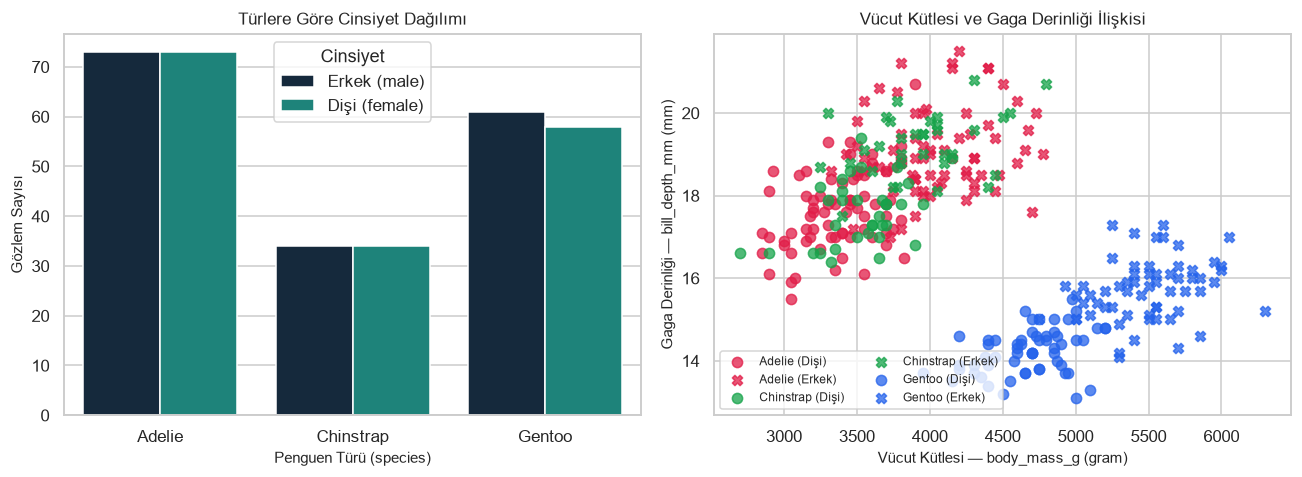

In [9]:
fig, eksenler = plt.subplots(1, 2, figsize=(12, 4.5))

sns.countplot(
    data=penguins_df,
    x="species",
    hue="sex",
    palette={"female": "#0d9488", "male": "#0f2942"},
    ax=eksenler[0],
)
eksenler[0].set_title("Türlere Göre Cinsiyet Dağılımı")
eksenler[0].set_xlabel("Penguen Türü (species)")
eksenler[0].set_ylabel("Gözlem Sayısı")
eksenler[0].legend(title="Cinsiyet", labels=["Erkek (male)", "Dişi (female)"])

semboller = {"female": "o", "male": "X"}
renkler_tur = {"Adelie": "#e11d48", "Chinstrap": "#16a34a", "Gentoo": "#2563eb"}
for (tur, cins), alt_df in penguins_df.groupby(["species", "sex"]):
    eksenler[1].scatter(
        alt_df["body_mass_g"],
        alt_df["bill_depth_mm"],
        c=renkler_tur[tur],
        marker=semboller[cins],
        alpha=0.75,
        s=45,
        label=f"{tur} ({'Dişi' if cins == 'female' else 'Erkek'})",
    )
eksenler[1].set_title("Vücut Kütlesi ve Gaga Derinliği İlişkisi")
eksenler[1].set_xlabel("Vücut Kütlesi — body_mass_g (gram)")
eksenler[1].set_ylabel("Gaga Derinliği — bill_depth_mm (mm)")
eksenler[1].legend(fontsize=8, loc="lower left", ncol=2)

plt.tight_layout()
plt.show()

**Yorum:** Sol grafik her üç penguen türünde de (*Adelie*, *Chinstrap*, *Gentoo*) kadın-erkek sayılarının dengeli olduğunu gösterir. Sağ grafik ise kitabın 21. bölümünde göreceğimiz kritik bir ipucunu barındırır: tek başına "ağır penguen erkektir" kuralı her zaman çalışmaz! Örneğin 4.500 gramlık bir *Gentoo* pengueni çoğunlukla **dişi** iken, 4.500 gramlık bir *Adelie* pengueni neredeyse kesinlikle **erkektir**. Yani vücut kütlesinin cinsiyet üzerindeki anlamı, penguenin **türüne** ve **gaga derinliğine** bağlıdır; işte özelliklerin birbirinin anlamını değiştirmesi durumuna **özellik etkileşimi** diyoruz.

<a id="bolum-21"></a>
<a id="bolum-21-1"></a>
## Bölüm 21: Özellik Etkileşimi (Feature Interaction)

Bir tahmin modelinde özellikler birbirleriyle etkileşime girdiğinde, bir özelliğin tahmine yaptığı katkı diğer özelliğin değerine göre değişir. Bu yüzden model tahmini, tekil özellik etkilerinin basit bir toplamı olarak yazılamaz; Aristoteles'in deyişiyle *"Bütün, parçalarının toplamından büyüktür."*

### 1.1 Ev Fiyatı Tahmin Tablolarının Oluşturulması — Kitaptaki etkileşimsiz (Tablo 1) ve etkileşimli (Tablo 2) ev fiyatı örneklerinin DataFrame olarak tanımlanması.

In [10]:
tablo_1_etkilesimsiz = pd.DataFrame({
    "Konum": ["iyi", "iyi", "kötü", "kötü"],
    "Büyüklük": ["büyük", "küçük", "büyük", "küçük"],
    "Tahmin (TL)": [300_000, 200_000, 250_000, 150_000],
})

tablo_2_etkilesimli = pd.DataFrame({
    "Konum": ["iyi", "iyi", "kötü", "kötü"],
    "Büyüklük": ["büyük", "küçük", "büyük", "küçük"],
    "Tahmin (TL)": [400_000, 200_000, 250_000, 150_000],
})

karsilastirma_ev = tablo_1_etkilesimsiz[["Konum", "Büyüklük"]].copy()
karsilastirma_ev["Tablo 1: Etkileşimsiz Tahmin"] = tablo_1_etkilesimsiz["Tahmin (TL)"]
karsilastirma_ev["Tablo 2: Etkileşimli Tahmin"] = tablo_2_etkilesimli["Tahmin (TL)"]
karsilastirma_ev

,Konum,Büyüklük,Tablo 1: Etkileşimsiz Tahmin,Tablo 2: Etkileşimli Tahmin
0,iyi,büyük,300000,400000
1,iyi,küçük,200000,200000
2,kötü,büyük,250000,250000
3,kötü,küçük,150000,150000


### Ev Fiyatı Tahmininin Bileşenlere Ayrıştırılması — İyi konumdaki büyük ev için 150.000 + 50.000 + 100.000 + 100.000 = 400.000 ayrıştırmasının kodla doğrulanması.

In [11]:
taban_fiyat = 150_000        # Kötü konum ve küçük ev başlangıç (sabit) değeri
iyi_konum_etkisi = 50_000    # Konum 'iyi' olduğunda eklenen tekil ana etki
buyuk_ev_etkisi = 100_000    # Büyüklük 'büyük' olduğunda eklenen tekil ana etki
etkilesim_etkisi = 100_000   # Yalnızca hem 'iyi' konum hem 'büyük' ev olduğunda eklenen etkileşim

iyi_buyuk_tablo1 = taban_fiyat + iyi_konum_etkisi + buyuk_ev_etkisi
iyi_buyuk_tablo2 = taban_fiyat + iyi_konum_etkisi + buyuk_ev_etkisi + etkilesim_etkisi

assert iyi_buyuk_tablo1 == 300_000, "Tablo 1 ayrıştırma hatası!"
assert iyi_buyuk_tablo2 == 400_000, "Tablo 2 ayrıştırma hatası!"

ayristirma_df = tablo_2_etkilesimli.copy()
ayristirma_df["Sabit Taban"] = taban_fiyat
ayristirma_df["Konum Ana Etkisi"] = np.where(ayristirma_df["Konum"] == "iyi", iyi_konum_etkisi, 0)
ayristirma_df["Büyüklük Ana Etkisi"] = np.where(ayristirma_df["Büyüklük"] == "büyük", buyuk_ev_etkisi, 0)
ayristirma_df["Etkileşim Etkisi"] = np.where(
    (ayristirma_df["Konum"] == "iyi") & (ayristirma_df["Büyüklük"] == "büyük"),
    etkilesim_etkisi,
    0,
)
ayristirma_df["Bileşen Toplamı"] = (
    ayristirma_df["Sabit Taban"]
    + ayristirma_df["Konum Ana Etkisi"]
    + ayristirma_df["Büyüklük Ana Etkisi"]
    + ayristirma_df["Etkileşim Etkisi"]
)
assert np.array_equal(ayristirma_df["Tahmin (TL)"], ayristirma_df["Bileşen Toplamı"])

print(
    f"İyi konum + Büyük ev ayrıştırması: "
    f"{taban_fiyat:,} + {iyi_konum_etkisi:,} + {buyuk_ev_etkisi:,} + {etkilesim_etkisi:,} = {iyi_buyuk_tablo2:,}"
)
ayristirma_df

İyi konum + Büyük ev ayrıştırması: 150,000 + 50,000 + 100,000 + 100,000 = 400,000


,Konum,Büyüklük,Tahmin (TL),Sabit Taban,Konum Ana Etkisi,Büyüklük Ana Etkisi,Etkileşim Etkisi,Bileşen Toplamı
0,iyi,büyük,400000,150000,50000,100000,100000,400000
1,iyi,küçük,200000,150000,50000,0,0,200000
2,kötü,büyük,250000,150000,0,100000,0,250000
3,kötü,küçük,150000,150000,0,0,0,150000


**Yorum:** Burada üç temel terimle tanışıyoruz: **Sabit terim (taban değer)** tüm tahminlerin başladığı temel fiyattır (`150.000`). **Ana etki**, bir özelliğin tek başına yaptığı katkıdır (konumun iyi olması `+50.000`, evin büyük olması `+100.000`). Tablo 1'de evi küçükten büyüğe çıkarmak kötü konumda da iyi konumda da fiyata tam `+100.000` ekler; yani özellikler birbirinden habersizdir (etkileşim yoktur). Oysa Tablo 2'de evi büyütmek kötü konumda `+100.000` kazandırırken iyi konumda `+200.000` kazandırır; aradaki fazladan `+100.000` yalnızca iki koşul aynı anda sağlandığında doğan **etkileşim etkisidir**.

### Ev Fiyatı Etkileşim ve Yığılmış Bileşen Grafikleri — Paralel eğim kontrolü için etkileşim grafiğinin ve bileşen katkıları için yığılmış çubuk grafiğinin çizdirilmesi.

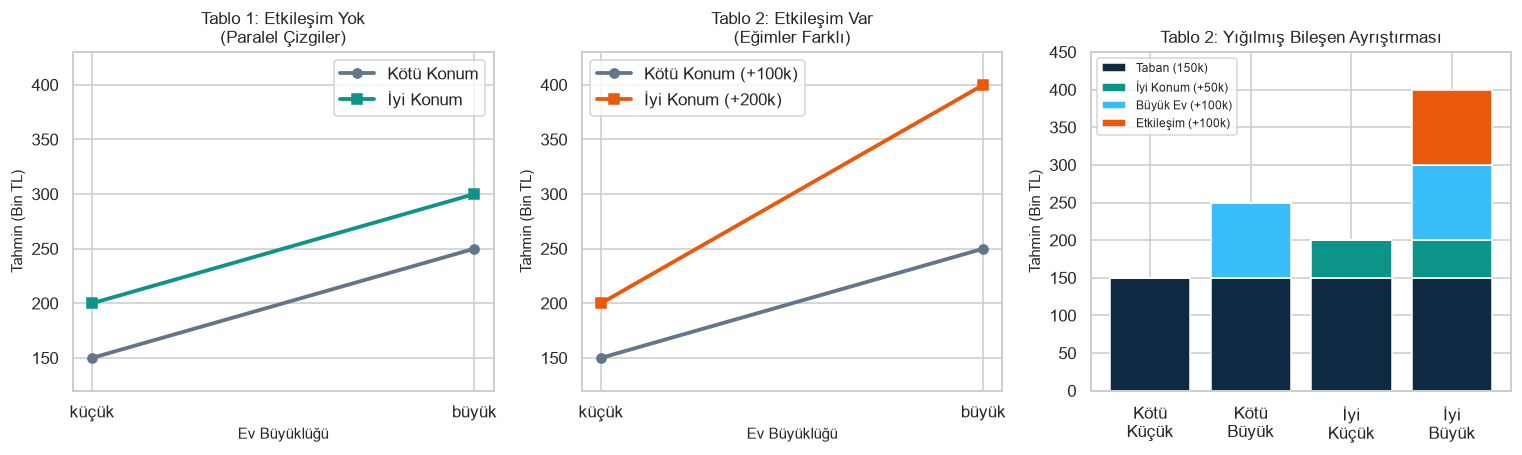

In [12]:
fig, eksenler = plt.subplots(1, 3, figsize=(14, 4.3))

# 1) Tablo 1 etkileşim grafiği (paralel doğrular)
eksenler[0].plot(["küçük", "büyük"], [150, 250], marker="o", linewidth=2.5, color="#64748b", label="Kötü Konum")
eksenler[0].plot(["küçük", "büyük"], [200, 300], marker="s", linewidth=2.5, color="#0d9488", label="İyi Konum")
eksenler[0].set_ylim(120, 430)
eksenler[0].set_title("Tablo 1: Etkileşim Yok\n(Paralel Çizgiler)")
eksenler[0].set_xlabel("Ev Büyüklüğü")
eksenler[0].set_ylabel("Tahmin (Bin TL)")
eksenler[0].legend()

# 2) Tablo 2 etkileşim grafiği (paralel olmayan doğrular)
eksenler[1].plot(["küçük", "büyük"], [150, 250], marker="o", linewidth=2.5, color="#64748b", label="Kötü Konum (+100k)")
eksenler[1].plot(["küçük", "büyük"], [200, 400], marker="s", linewidth=2.5, color="#ea580c", label="İyi Konum (+200k)")
eksenler[1].set_ylim(120, 430)
eksenler[1].set_title("Tablo 2: Etkileşim Var\n(Eğimler Farklı)")
eksenler[1].set_xlabel("Ev Büyüklüğü")
eksenler[1].set_ylabel("Tahmin (Bin TL)")
eksenler[1].legend()

# 3) Tablo 2 yığılmış çubuk grafik
etiketler_ev = ["Kötü\nKüçük", "Kötü\nBüyük", "İyi\nKüçük", "İyi\nBüyük"]
sira = [3, 2, 1, 0]
taban_b = ayristirma_df.iloc[sira]["Sabit Taban"].to_numpy() / 1000
konum_b = ayristirma_df.iloc[sira]["Konum Ana Etkisi"].to_numpy() / 1000
buyuk_b = ayristirma_df.iloc[sira]["Büyüklük Ana Etkisi"].to_numpy() / 1000
etk_b = ayristirma_df.iloc[sira]["Etkileşim Etkisi"].to_numpy() / 1000

eksenler[2].bar(etiketler_ev, taban_b, label="Taban (150k)", color="#0f2942")
eksenler[2].bar(etiketler_ev, konum_b, bottom=taban_b, label="İyi Konum (+50k)", color="#0d9488")
eksenler[2].bar(etiketler_ev, buyuk_b, bottom=taban_b + konum_b, label="Büyük Ev (+100k)", color="#38bdf8")
eksenler[2].bar(etiketler_ev, etk_b, bottom=taban_b + konum_b + buyuk_b, label="Etkileşim (+100k)", color="#ea580c")
eksenler[2].set_ylim(0, 450)
eksenler[2].set_title("Tablo 2: Yığılmış Bileşen Ayrıştırması")
eksenler[2].set_ylabel("Tahmin (Bin TL)")
eksenler[2].legend(fontsize=8, loc="upper left")

plt.tight_layout()
plt.show()

**Yorum:** Sol grafikte çizgiler birbirine **tam paraleldir**; bir özelliğin (büyüklüğün) etkisi diğer özellik (konum) değiştiğinde aynı kaldığı sürece çizgiler paralel kalır ve etkileşim sıfırdır. Orta grafikte ise iyi konum çizgisi çok daha dik yükselir; paralelliğin bozulması görsel olarak etkileşimin kanıtıdır. Sağdaki yığılmış çubuk grafikte turuncu renkli `+100k` etkileşim bloğunun yalnızca "İyi + Büyük" sütununda belirdiğine dikkat edin.

<a id="bolum-21-2"></a>
### 1.2 Friedman'ın H-İstatistiği: Matematiksel Temel — Kısmi bağımlılık ayrıştırması ve ikili/toplam etkileşim gücü formülleri.

Gerçek modellerde yüzlerce tahmin noktası bulunduğundan etkileşimin gücünü tek bir sayıyla özetlemek için Friedman ve Popescu (2008) tarafından önerilen **H-istatistiği** kullanılır. Bu ölçü **Kısmi Bağımlılık (Partial Dependence - PD)** fonksiyonuna dayanır. Kısmi bağımlılık, ilgilendiğimiz özelliğin değerini sabitleyip diğer tüm özellikleri veri setindeki gerçek değerleri üzerinden ortalamaya (marjinalleştirmeye) tabi tutarak modelin ortalama tepkisini ölçer.

Eğer $j$ ve $k$ özellikleri arasında **hiç etkileşim yoksa**, sıfır ortalamalı (merkezlenmiş) iki yönlü kısmi bağımlılık fonksiyonu tekil kısmi bağımlılıkların toplamına eşittir:

$$PD_{jk}(x_j, x_k) = PD_j(x_j) + PD_k(x_k)$$

Benzer biçimde, $j$ özelliğinin modeldeki **diğer hiçbir özellikle etkileşimi yoksa**, merkezlenmiş tahmin fonksiyonu $\hat{f}(\mathbf{x})$, yalnızca $j$'ye bağlı kısmi bağımlılık ile $j$ dışındaki tüm özelliklere bağlı kısmi bağımlılığın ($PD_{-j}$) toplamı olarak yazılabilir:

$$\hat{f}(\mathbf{x}) = PD_j(x_j) + PD_{-j}(\mathbf{x}_{-j})$$

**Kelimelerle anlamı:** Sol taraf modelin birlikte ürettiği gerçek davranışı, sağ taraf ise "etkileşim olmasaydı parçaların toplamı ne olurdu?" sorusunun cevabını verir. İkisi arasındaki fark ne kadar büyükse etkileşim o kadar güçlüdür!

Bu farkın kareler toplamını (etkileşim varyansını) toplam varyansa oranladığımızda **ikili H-istatistiği** ($H^2_{jk}$) ve **toplam H-istatistiği** ($H^2_j$) elde edilir:

$$H^2_{jk} = \frac{\sum_{i=1}^n\left[PD_{jk}\!\left(x_{j}^{(i)},x_k^{(i)}\right) - PD_j\!\left(x_j^{(i)}\right) - PD_k\!\left(x_{k}^{(i)}\right)\right]^2}{\sum_{i=1}^n\left(PD_{jk}\!\left(x_j^{(i)},x_k^{(i)}\right)\right)^2}$$

$$H^2_{j} = \frac{\sum_{i=1}^n\left[\hat{f}\!\left(\mathbf{x}^{(i)}\right) - PD_j\!\left(x^{(i)}_j\right) - PD_{-j}\!\left(\mathbf{x}_{-j}^{(i)}\right)\right]^2}{\sum_{i=1}^n \left(\hat{f}\!\left(\mathbf{x}^{(i)}\right)\right)^2}$$

**Kelimelerle anlamı:** Pay kısmı "toplamsallıktan sapma miktarını (etkileşim kaynaklı değişimi)", payda kısmı ise "fonksiyonun toplam değişimini (varyansını)" ölçer. Raporlanırken genellikle karekökü olan $H_{jk} = \sqrt{H^2_{jk}}$ ve $H_j = \sqrt{H^2_j}$ kullanılır:
- $H = 0$ ise özellikler arasında **hiç etkileşim yoktur** (etki tamamen toplamsaldır).
- $H = 1$ ise tekil $PD$ fonksiyonları sabittir ve varyansın **tamamı etkileşimden** kaynaklanır.
- $H > 1$ değeri de matematiksel olarak mümkündür: etkileşim teriminin varyansı, tekil etkilerle ters yönlü sönümleme yarattığında paydadaki birleşik varyanstan daha büyük çıkabilir.

### Kısmi Bağımlılık (PD) Fonksiyonlarının Kodlanması — 1 boyutlu, 2 boyutlu ve j-hariç kısmi bağımlılık hesaplarının saf numpy ile yazılması.

In [13]:
def kismi_bagimlilik_1b(tahmin_fn, X: np.ndarray, j: int, izgara_j: np.ndarray, merkezle: bool = True) -> np.ndarray:
    '''j. özellik için 1 boyutlu kısmi bağımlılık (PD_j) değerlerini hesaplar.'''
    X = np.asarray(X, dtype=float)
    izgara_j = np.asarray(izgara_j, dtype=float).ravel()
    n = X.shape[0]
    m = izgara_j.shape[0]

    # Her ızgara noktası için tüm n veri satırını kopyalayıp j. sütunu sabitle
    X_tekrar = np.tile(X, (m, 1))
    X_tekrar[:, j] = np.repeat(izgara_j, n)
    tahminler = np.asarray(tahmin_fn(X_tekrar), dtype=float).reshape(m, n)
    pd_degerleri = tahminler.mean(axis=1)
    if merkezle:
        pd_degerleri = pd_degerleri - pd_degerleri.mean()
    return pd_degerleri


def kismi_bagimlilik_2b_noktalar(
    tahmin_fn, X: np.ndarray, j: int, k: int, noktalar_jk: np.ndarray, merkezle: bool = True
) -> np.ndarray:
    '''Verilen (x_j^(i), x_k^(i)) çiftleri üzerinde 2 yönlü PD_jk değerlerini hesaplar.'''
    X = np.asarray(X, dtype=float)
    noktalar_jk = np.asarray(noktalar_jk, dtype=float)
    n = X.shape[0]
    m = noktalar_jk.shape[0]

    X_tekrar = np.tile(X, (m, 1))
    X_tekrar[:, j] = np.repeat(noktalar_jk[:, 0], n)
    X_tekrar[:, k] = np.repeat(noktalar_jk[:, 1], n)
    tahminler = np.asarray(tahmin_fn(X_tekrar), dtype=float).reshape(m, n)
    pd_jk = tahminler.mean(axis=1)
    if merkezle:
        pd_jk = pd_jk - pd_jk.mean()
    return pd_jk


def kismi_bagimlilik_2b_izgara(
    tahmin_fn, X: np.ndarray, j: int, k: int, izgara_j: np.ndarray, izgara_k: np.ndarray, merkezle: bool = False
) -> np.ndarray:
    '''Isı haritası çizimi için 2 boyutlu (m_k x m_j) PD_jk ızgarasını hesaplar.'''
    izgara_j = np.asarray(izgara_j, dtype=float).ravel()
    izgara_k = np.asarray(izgara_k, dtype=float).ravel()
    JJ, KK = np.meshgrid(izgara_j, izgara_k)
    ciftler = np.column_stack([JJ.ravel(), KK.ravel()])
    pd_duz = kismi_bagimlilik_2b_noktalar(tahmin_fn, X, j, k, ciftler, merkezle=merkezle)
    return pd_duz.reshape(len(izgara_k), len(izgara_j))


def kismi_bagimlilik_eksi_j(tahmin_fn, X: np.ndarray, j: int, X_ornek: np.ndarray, merkezle: bool = True) -> np.ndarray:
    '''j. özellik dışındaki tüm özellikler sabitken j üzerinden ortalama alan PD_{-j} hesabı.'''
    X = np.asarray(X, dtype=float)
    X_ornek = np.asarray(X_ornek, dtype=float)
    n = X.shape[0]
    m = X_ornek.shape[0]

    # her örnek satırını n kez tekrarla, yalnızca j. sütuna tüm verideki x_j değerlerini koy
    X_tekrar = np.repeat(X_ornek, n, axis=0)
    X_tekrar[:, j] = np.tile(X[:, j], m)
    tahminler = np.asarray(tahmin_fn(X_tekrar), dtype=float).reshape(m, n)
    pd_eksi_j = tahminler.mean(axis=1)
    if merkezle:
        pd_eksi_j = pd_eksi_j - pd_eksi_j.mean()
    return pd_eksi_j

### İkili ve Toplam H-İstatistiği Fonksiyonlarının Kodlanması — Friedman'ın $H_{jk}$, $H_j$ ve normalize edilmemiş $H^*_{jk}$ ölçütlerinin saf numpy ile yazılması.

In [14]:
def h_istatistigi_ikili(
    tahmin_fn, X: np.ndarray, j: int, k: int, orneklem_boyutu: int = 150, tohum: int = 42
) -> dict:
    '''j ve k özellikleri arasındaki ikili H_jk, H^2_jk ve normalize edilmemiş H*_jk değerlerini hesaplar.'''
    X = np.asarray(X, dtype=float)
    rng = np.random.default_rng(tohum)
    if orneklem_boyutu is not None and X.shape[0] > orneklem_boyutu:
        indisler = rng.choice(X.shape[0], size=orneklem_boyutu, replace=False)
        X_alt = X[indisler]
    else:
        X_alt = X

    pd_j = kismi_bagimlilik_1b(tahmin_fn, X_alt, j, X_alt[:, j], merkezle=True)
    pd_k = kismi_bagimlilik_1b(tahmin_fn, X_alt, k, X_alt[:, k], merkezle=True)
    pd_jk = kismi_bagimlilik_2b_noktalar(tahmin_fn, X_alt, j, k, X_alt[:, [j, k]], merkezle=True)

    fark_kare_toplam = float(np.sum((pd_jk - pd_j - pd_k) ** 2))
    payda = float(np.sum(pd_jk ** 2))
    h_kare = 0.0 if payda < 1e-15 else fark_kare_toplam / payda
    h_degeri = float(np.sqrt(max(0.0, h_kare)))
    h_yildiz = float(np.sqrt(max(0.0, fark_kare_toplam)))
    return {"H": h_degeri, "H2": h_kare, "H_yildiz": h_yildiz, "payda": payda}


def h_istatistigi_toplam(
    tahmin_fn, X: np.ndarray, j: int, orneklem_boyutu: int = 150, tohum: int = 42
) -> dict:
    '''j. özelliğin diğer tüm özelliklerle olan toplam etkileşim gücünü (H_j) hesaplar.'''
    X = np.asarray(X, dtype=float)
    rng = np.random.default_rng(tohum)
    if orneklem_boyutu is not None and X.shape[0] > orneklem_boyutu:
        indisler = rng.choice(X.shape[0], size=orneklem_boyutu, replace=False)
        X_alt = X[indisler]
    else:
        X_alt = X

    f_merkez = np.asarray(tahmin_fn(X_alt), dtype=float).ravel()
    f_merkez = f_merkez - f_merkez.mean()
    pd_j = kismi_bagimlilik_1b(tahmin_fn, X_alt, j, X_alt[:, j], merkezle=True)
    pd_eksi_j = kismi_bagimlilik_eksi_j(tahmin_fn, X_alt, j, X_alt, merkezle=True)

    fark_kare_toplam = float(np.sum((f_merkez - pd_j - pd_eksi_j) ** 2))
    payda = float(np.sum(f_merkez ** 2))
    h_kare = 0.0 if payda < 1e-15 else fark_kare_toplam / payda
    h_degeri = float(np.sqrt(max(0.0, h_kare)))
    return {"H": h_degeri, "H2": h_kare, "payda": payda}

**Ek örnek (kitapta yok)**

### H-İstatistiğinin Kuramsal Sınırlarının Doğrulanması — Toplamsal modelde ($f = x_1 + x_2$) $H \approx 0$, saf çarpım modelinde ($f = x_1 \cdot x_2$) $H \approx 1$ ve ters yönlü ana etkilerde $H > 1$ olduğunun `assert` ile sınanması.

In [15]:
rng_dogrulama = np.random.default_rng(TOHUM)
X_sentetik = rng_dogrulama.uniform(-1.0, 1.0, size=(120, 2))
# Sıfır ortalama simetrisi için tam merkezli girdi matrisi
X_sentetik = X_sentetik - X_sentetik.mean(axis=0, keepdims=True)

# 1) Tamamen toplamsal fonksiyon: f(x1, x2) = x1 + x2 -> Etkileşim yok (H = 0)
toplamsal_sonuc = h_istatistigi_ikili(lambda Z: Z[:, 0] + Z[:, 1], X_sentetik, 0, 1, orneklem_boyutu=None)

# 2) Sıfır ortalamalı saf çarpım fonksiyonu: f(x1, x2) = x1 * x2 -> Saf etkileşim (H = 1)
carpim_sonuc = h_istatistigi_ikili(lambda Z: Z[:, 0] * Z[:, 1], X_sentetik, 0, 1, orneklem_boyutu=None)

# 3) H > 1 olabilen durum: f(x1, x2) = (x1 - x2)^2 = x1^2 + x2^2 - 2*x1*x2 (korelasyonlu x1 ≈ x2 altında
#    köşegen üzerinde -2*x1*x2 etkileşimi ana etkileri sönümleyerek PD_12 varyansını küçültür -> H > 1)
u_korel = rng_dogrulama.normal(0.0, 1.0, size=120)
X_bagimli = np.column_stack([u_korel, u_korel + rng_dogrulama.normal(0.0, 0.35, size=120)])
h_buyuk_1_sonuc = h_istatistigi_ikili(
    lambda Z: (Z[:, 0] - Z[:, 1]) ** 2, X_bagimli, 0, 1, orneklem_boyutu=None
)

assert toplamsal_sonuc["H"] < 1e-12, f"Toplamsal modelde H sıfır olmalıydı, bulunan: {toplamsal_sonuc['H']}"
assert abs(carpim_sonuc["H"] - 1.0) < 1e-12, f"Saf çarpımda H=1 olmalıydı, bulunan: {carpim_sonuc['H']}"
assert h_buyuk_1_sonuc["H"] > 1.0, f"Ters sönümlemeli örnekte H>1 bekleniyordu, bulunan: {h_buyuk_1_sonuc['H']}"

dogrulama_tablosu = pd.DataFrame([
    {"Senaryo": "Toplamsal Model: f(x1, x2) = x1 + x2", "Beklenen": "H ≈ 0", "Hesaplanan H": round(toplamsal_sonuc["H"], 8), "Durum": "✓ Geçti"},
    {"Senaryo": "Saf Çarpım (sıfır ort.): f(x1, x2) = x1 · x2", "Beklenen": "H ≈ 1", "Hesaplanan H": round(carpim_sonuc["H"], 8), "Durum": "✓ Geçti"},
    {"Senaryo": "Ters Sönümlemeli Etkileşim (korelasyonlu)", "Beklenen": "H > 1", "Hesaplanan H": round(h_buyuk_1_sonuc["H"], 4), "Durum": "✓ Geçti"},
])
dogrulama_tablosu

,Senaryo,Beklenen,Hesaplanan H,Durum
0,"Toplamsal Model: f(x1, x2) = x1 + x2",H ≈ 0,0.0000,✓ Geçti
1,"Saf Çarpım (sıfır ort.): f(x1, x2) = x1 · x2",H ≈ 1,1.0000,✓ Geçti
2,Ters Sönümlemeli Etkileşim (korelasyonlu),H > 1,18.7741,✓ Geçti


**Yorum:** Sıfırdan yazdığımız `numpy` fonksiyonları matematiksel teoriyi tam isabetle doğrulamaktadır: $f(x_1, x_2) = x_1 + x_2$ modelinde özellikler birbirine hiç karışmadığı için $H_{12} = 0$ çıkmıştır. Girdileri sıfır etrafında dengeli olan $f(x_1, x_2) = x_1 \cdot x_2$ modelinde ise bir özelliğin ortalama tekil etkisi sıfır olduğundan tüm değişim çarpım teriminden gelir ve $H_{12} = 1$ bulunur. Üçüncü satır ise kitapta vurgulanan önemli bir sınırlılığı gösterir: etkileşim terimi ana etkilerle zıt yönde çalışıp toplam varyansı küçülttüğünde $H$ değeri **1'den büyük** çıkabilir; bu yüzden $H$'yi her zaman basit bir "yüzde (0–100%)" gibi okumamak gerekir.

<a id="bolum-21-3"></a>
### 1.3 Penguen Cinsiyet Tahmini İçin Modellerin Eğitilmesi — Rastgele Orman, Gradyan Artırma ve Lojistik Regresyon modellerinin veri sızıntısı olmadan eğitilip değerlendirilmesi.

In [16]:
OZELLIK_ADLARI = ["species", "bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
TUR_SIRASI = ["Adelie", "Chinstrap", "Gentoo"]
TUR_KOD_HARITASI = {ad: kod for kod, ad in enumerate(TUR_SIRASI)}

# species sütununu tek bir özellik sütunu olarak korumak için tamsayı koduna çevirip Pipeline içinde OneHot uyguluyoruz
X_tum = penguins_df[OZELLIK_ADLARI].copy()
X_tum["species"] = X_tum["species"].map(TUR_KOD_HARITASI).astype(float)
X_matris = X_tum.to_numpy(dtype=float)
y_vektor = penguins_df["hedef_disi"].to_numpy(dtype=int)

# Ön işleme adımlarından ÖNCE eğitim/test ayrımı (veri sızıntısını önlemek için)
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X_matris, y_vektor, test_size=0.25, random_state=TOHUM, stratify=y_vektor
)

agac_on_isleme = ColumnTransformer([
    ("tur_ohe", OneHotEncoder(categories=[[0.0, 1.0, 2.0]], sparse_output=False), [0]),
    ("sayisal", "passthrough", [1, 2, 3, 4]),
])

dogrusal_on_isleme = ColumnTransformer([
    ("tur_ohe", OneHotEncoder(categories=[[0.0, 1.0, 2.0]], drop="first", sparse_output=False), [0]),
    ("sayisal_olcek", StandardScaler(), [1, 2, 3, 4]),
])

modeller = {
    "Rastgele Orman": Pipeline([
        ("on_isleme", agac_on_isleme),
        ("model", RandomForestClassifier(n_estimators=50, random_state=TOHUM)),
    ]),
    "Gradyan Artırma": Pipeline([
        ("on_isleme", agac_on_isleme),
        ("model", GradientBoostingClassifier(n_estimators=50, max_depth=3, random_state=TOHUM)),
    ]),
    "Lojistik Regresyon": Pipeline([
        ("on_isleme", dogrusal_on_isleme),
        ("model", LogisticRegression(C=0.2, random_state=TOHUM, max_iter=500)),
    ]),
}

performans_satirlari = []
for model_adi, boru_hatti in modeller.items():
    boru_hatti.fit(X_egitim, y_egitim)
    y_tahmin = boru_hatti.predict(X_test)
    dogruluk = accuracy_score(y_test, y_tahmin)
    performans_satirlari.append({
        "Model": model_adi,
        "Eğitim Doğruluğu": round(accuracy_score(y_egitim, boru_hatti.predict(X_egitim)), 4),
        "Test Doğruluğu": round(dogruluk, 4),
    })
    print(f"=== {model_adi} (Test Doğruluğu: {dogruluk:.2%}) ===")
    print(classification_report(y_test, y_tahmin, target_names=["Erkek (0)", "Dişi (1)"], digits=3))

pd.DataFrame(performans_satirlari)

=== Rastgele Orman (Test Doğruluğu: 90.48%) ===
              precision    recall  f1-score   support

   Erkek (0)      0.840     1.000     0.913        42
    Dişi (1)      1.000     0.810     0.895        42

    accuracy                          0.905        84
   macro avg      0.920     0.905     0.904        84
weighted avg      0.920     0.905     0.904        84

=== Gradyan Artırma (Test Doğruluğu: 95.24%) ===
              precision    recall  f1-score   support

   Erkek (0)      0.932     0.976     0.953        42
    Dişi (1)      0.975     0.929     0.951        42

    accuracy                          0.952        84
   macro avg      0.953     0.952     0.952        84
weighted avg      0.953     0.952     0.952        84

=== Lojistik Regresyon (Test Doğruluğu: 89.29%) ===
              precision    recall  f1-score   support

   Erkek (0)      0.851     0.952     0.899        42
    Dişi (1)      0.946     0.833     0.886        42

    accuracy                     

,Model,Eğitim Doğruluğu,Test Doğruluğu
0,Rastgele Orman,1.0000,0.9048
1,Gradyan Artırma,0.9839,0.9524
2,Lojistik Regresyon,0.9036,0.8929


**Yorum:** Üç model de test verisi üzerinde **%89,3 – %95,2** aralığında yüksek sınıflandırma doğruluğuna ulaşmıştır (**kesinlik / precision**, dişi dediklerimizin ne kadarının gerçekten dişi olduğunu; **duyarlılık / recall**, gerçek dişilerin ne kadarını yakaladığımızı; **F1-skoru** ise ikisinin dengeli ortalamasını gösterir). Sırf doğruluk oranlarına baksaydık üç modelin içerde aynı mantıkla karar verdiğini sanabilirdik; şimdi H-istatistiği ile modellerin iç yapısındaki özellik etkileşimlerini mercek altına alalım.

### Penguen Rastgele Orman Modelinde Toplam ve İkili H-İstatistiği — Kitaptaki penguen örneğine uygun olarak tüm özelliklerin toplam $H_j$ gücünün ve `body_mass_g` ikili $H_{jk}$ etkileşimlerinin çizdirilmesi.

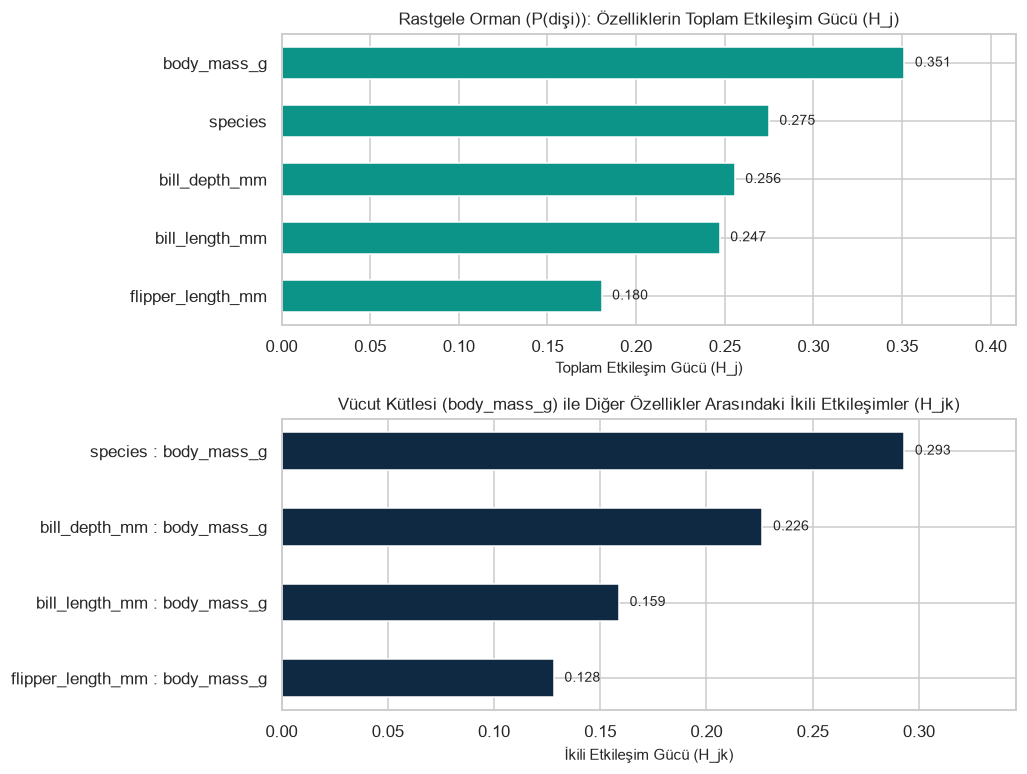

In [17]:
rf_olasilik_fn = lambda Z: modeller["Rastgele Orman"].predict_proba(Z)[:, 1]

# 1) Her özellik için toplam etkileşim gücü (H_j)
rf_toplam_h = {}
for j, oz_adi in enumerate(OZELLIK_ADLARI):
    rf_toplam_h[oz_adi] = h_istatistigi_toplam(rf_olasilik_fn, X_matris, j, orneklem_boyutu=150, tohum=TOHUM)["H"]

# 2) Vücut kütlesi (body_mass_g, indeks=4) ile diğer özellikler arasındaki ikili H_jk
hedef_indeks = OZELLIK_ADLARI.index("body_mass_g")
rf_ikili_h = {}
for k, oz_adi in enumerate(OZELLIK_ADLARI):
    if k != hedef_indeks:
        etiket = f"{oz_adi} : body_mass_g"
        rf_ikili_h[etiket] = h_istatistigi_ikili(
            rf_olasilik_fn, X_matris, hedef_indeks, k, orneklem_boyutu=150, tohum=TOHUM
        )["H"]

fig, eksenler = plt.subplots(2, 1, figsize=(9.5, 7.2))

# Üst panel: Toplam H_j
sira_toplam = sorted(rf_toplam_h.items(), key=lambda x: x[1])
eksenler[0].barh([x[0] for x in sira_toplam], [x[1] for x in sira_toplam], color="#0d9488", height=0.55)
for y_konum, (_, deger) in enumerate(sira_toplam):
    eksenler[0].text(deger + 0.006, y_konum, f"{deger:.3f}", va="center", fontsize=9)
eksenler[0].set_xlim(0, max(rf_toplam_h.values()) * 1.18)
eksenler[0].set_title("Rastgele Orman (P(dişi)): Özelliklerin Toplam Etkileşim Gücü (H_j)")
eksenler[0].set_xlabel("Toplam Etkileşim Gücü (H_j)")

# Alt panel: body_mass_g ile ikili H_jk
sira_ikili = sorted(rf_ikili_h.items(), key=lambda x: x[1])
eksenler[1].barh([x[0] for x in sira_ikili], [x[1] for x in sira_ikili], color="#0f2942", height=0.5)
for y_konum, (_, deger) in enumerate(sira_ikili):
    eksenler[1].text(deger + 0.005, y_konum, f"{deger:.3f}", va="center", fontsize=9)
eksenler[1].set_xlim(0, max(rf_ikili_h.values()) * 1.18)
eksenler[1].set_title("Vücut Kütlesi (body_mass_g) ile Diğer Özellikler Arasındaki İkili Etkileşimler (H_jk)")
eksenler[1].set_xlabel("İkili Etkileşim Gücü (H_jk)")

plt.tight_layout()
plt.show()

**Yorum:** Kitaptaki penguen analizinde olduğu gibi, Rastgele Orman modelinde diğer özelliklerle en güçlü etkileşime giren özellik açık ara **vücut kütlesi (`body_mass_g`)** ve **gaga derinliği (`bill_depth_mm`)** olmuştur. Alt grafiğe indiğimizde vücut kütlesinin en yoğun ikili etkileşimini **gaga derinliği (`bill_depth_mm : body_mass_g`)** ve **gaga uzunluğu / tür** ile kurduğu görülür. Biyolojik olarak bunun nedeni açıktır: bir penguenin kütlesinin "dişi mi erkek mi?" anlamına geldiğini çözmek için gaga yapısına ve türüne birlikte bakmak gerekir.

**Ek örnek (kitapta yok)**

### Üç Modelin (Rastgele Orman, Gradyan Artırma, Lojistik Regresyon) Etkileşim Karşılaştırması — Farklı model ailelerinde toplam $H_j$ değerlerinin hesaplanıp karşılaştırılması.

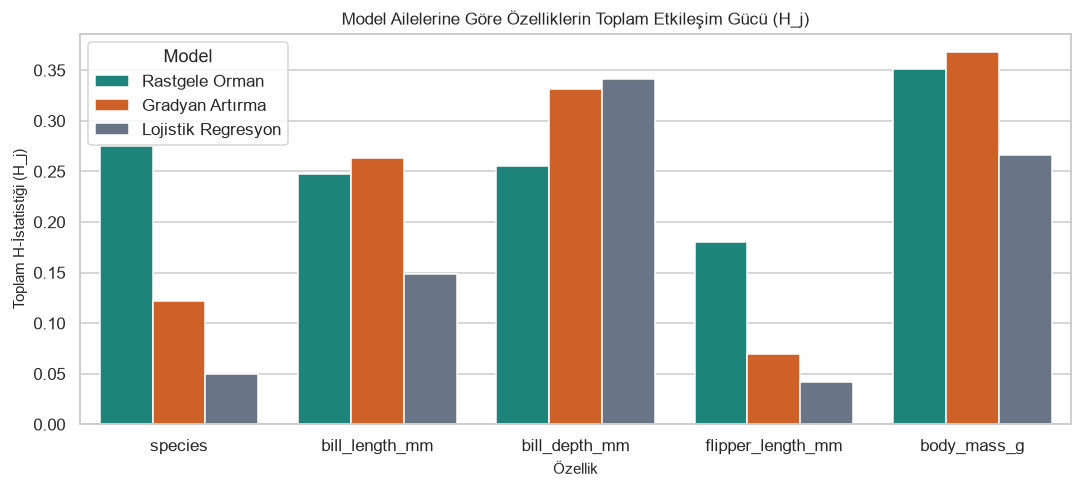

In [18]:
model_h_karsilastirma = []
for model_adi, boru_hatti in modeller.items():
    olasilik_fn = lambda Z, m=boru_hatti: m.predict_proba(Z)[:, 1]
    for j, oz_adi in enumerate(OZELLIK_ADLARI):
        h_deg = h_istatistigi_toplam(olasilik_fn, X_matris, j, orneklem_boyutu=150, tohum=TOHUM)["H"]
        model_h_karsilastirma.append({"Model": model_adi, "Özellik": oz_adi, "Toplam H": h_deg})

df_model_h = pd.DataFrame(model_h_karsilastirma)

# Doğrulama: Lojistik Regresyonun ortalama ve maksimum H değeri ağaç tabanlı Rastgele Orman'dan düşük olmalı
lr_maks_h = df_model_h[df_model_h["Model"] == "Lojistik Regresyon"]["Toplam H"].max()
rf_maks_h = df_model_h[df_model_h["Model"] == "Rastgele Orman"]["Toplam H"].max()
assert lr_maks_h < rf_maks_h, f"Lojistik regresyon H ({lr_maks_h:.3f}) < RF H ({rf_maks_h:.3f}) bekleniyordu!"

plt.figure(figsize=(10, 4.6))
sns.barplot(
    data=df_model_h,
    x="Özellik",
    y="Toplam H",
    hue="Model",
    palette={"Rastgele Orman": "#0d9488", "Gradyan Artırma": "#ea580c", "Lojistik Regresyon": "#64748b"},
)
plt.title("Model Ailelerine Göre Özelliklerin Toplam Etkileşim Gücü (H_j)")
plt.xlabel("Özellik")
plt.ylabel("Toplam H-İstatistiği (H_j)")
plt.legend(title="Model")
plt.tight_layout()
plt.show()

**Yorum (Lojistik Regresyonda Etkileşim Neden Düşüktür?):** Grafik çok öğretici bir farkı ortaya koyar: Karar ağaçlarına dayanan **Rastgele Orman** ve **Gradyan Artırma** modelleri, bir düğümde önce vücut kütlesine göre bölüp alt düğümde gaga derinliğine göre bölerek doğal "VE (AND)" kuralları (etkileşimler) kurar. **Lojistik Regresyon** ise içeride özellikleri çarpıştırmaz; log-bahis (logit) ölçeğinde tamamen toplamsal bir formül ($\eta = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p$) kullanır. Peki açıkça çarpım terimi koymadığımız halde Lojistik Regresyonun $H$ çubukları neden tam sıfır değil de küçük pozitif değerler (`~0.05 – 0.14`) aldı? Çünkü sınıflandırmada tahmin olasılığa dönüştürülürken doğrusal toplam, S-biçimli **sigmoid fonksiyonundan** ($P = 1 / (1 + e^{-\eta})$) geçirilir. Bu eğrisel sıkıştırma olasılık ölçeğinde hafif bir örtük bükülme yaratır; ancak ağaç modellerindeki gerçek yapısal etkileşimlerin yanında oldukça küçüktür.

### Penguen Türlerine Göre Etkileşim Gücü Analizi — Rastgele Orman modelinde *Adelie*, *Chinstrap* ve *Gentoo* alt grupları içinde özellik etkileşimlerinin ayrı ayrı hesaplanması.

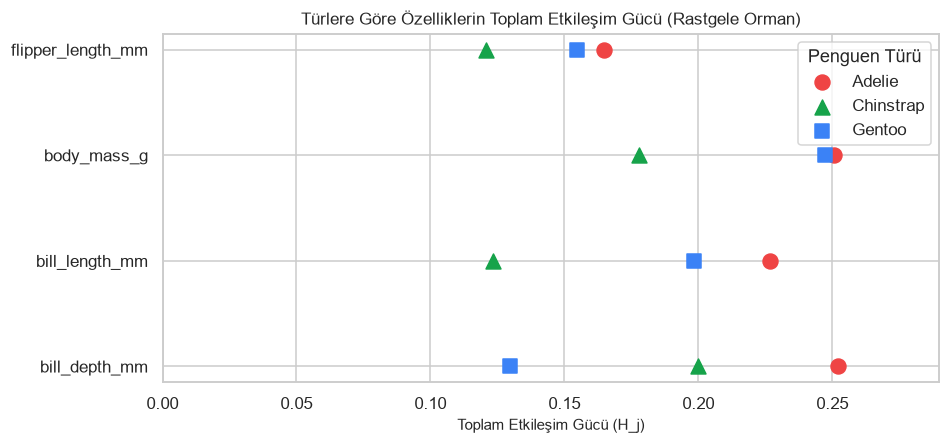

In [19]:
tur_bazli_satirlar = []
for tur_kodu, tur_adi in enumerate(TUR_SIRASI):
    X_tur = X_matris[X_matris[:, 0] == float(tur_kodu)]
    for j, oz_adi in enumerate(OZELLIK_ADLARI):
        if oz_adi == "species":
            continue  # Tür sabitlendiği için yalnızca fiziksel özellikler incelenir
        h_tur = h_istatistigi_toplam(rf_olasilik_fn, X_tur, j, orneklem_boyutu=150, tohum=TOHUM)["H"]
        tur_bazli_satirlar.append({"Tür": tur_adi, "Özellik": oz_adi, "Etkileşim Gücü (H)": h_tur})

df_tur_h = pd.DataFrame(tur_bazli_satirlar)

plt.figure(figsize=(8.8, 4.2))
tur_stilleri = {
    "Adelie": ("o", "#ef4444"),
    "Chinstrap": ("^", "#16a34a"),
    "Gentoo": ("s", "#3b82f6"),
}
ozellik_sirasi_tur = ["bill_depth_mm", "bill_length_mm", "body_mass_g", "flipper_length_mm"]
y_konumlari = {oz: idx for idx, oz in enumerate(ozellik_sirasi_tur)}

for tur_adi, (isaret, renk) in tur_stilleri.items():
    alt = df_tur_h[df_tur_h["Tür"] == tur_adi]
    plt.scatter(
        alt["Etkileşim Gücü (H)"],
        [y_konumlari[oz] for oz in alt["Özellik"]],
        marker=isaret,
        color=renk,
        s=95,
        label=tur_adi,
        zorder=3,
    )

plt.yticks(range(len(ozellik_sirasi_tur)), ozellik_sirasi_tur)
plt.xlim(0, df_tur_h["Etkileşim Gücü (H)"].max() * 1.15)
plt.xlabel("Toplam Etkileşim Gücü (H_j)")
plt.title("Türlere Göre Özelliklerin Toplam Etkileşim Gücü (Rastgele Orman)")
plt.legend(title="Penguen Türü")
plt.tight_layout()
plt.show()

**Yorum:** Kitaptaki *Bonus* grafiğinde gösterildiği üzere, özellik etkileşimlerinin şiddeti bir penguen türünden diğerine belirgin biçimde değişmektedir. Örneğin vücut kütlesi (`body_mass_g`) ve gaga ölçümleri arasındaki etkileşim gücü türler arasında aynı noktada toplanmaz; çünkü her türün vücut büyüklüğü aralığı farklıdır ve model her türün kendi fiziksel sınırları içinde farklı eşik kurallarını devreye sokar.

### Seçilen İki Özellik İçin 2 Boyutlu Kısmi Bağımlılık (2B PDP) Isı Haritası — En güçlü ikili etkileşime sahip `body_mass_g` ve `bill_depth_mm` özelliklerinin `P(dişi)` tahmin yüzeyinin görselleştirilmesi.

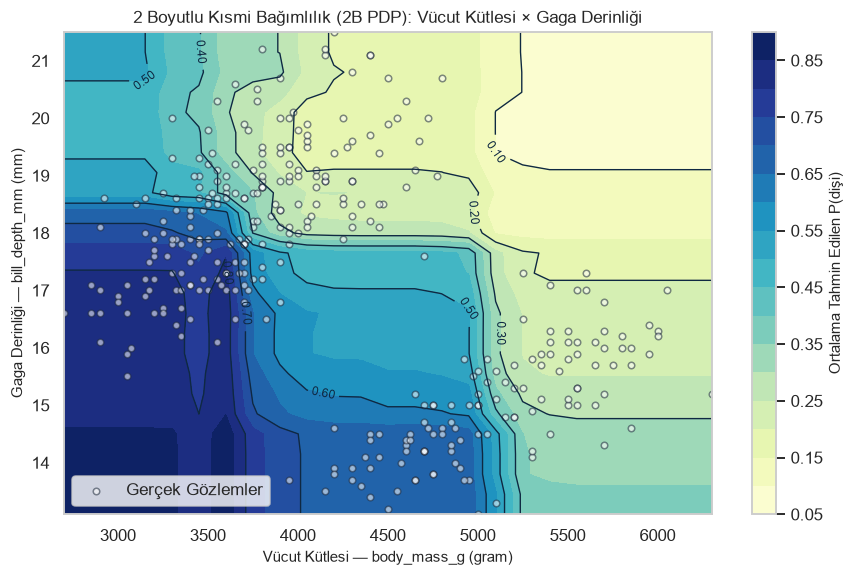

In [20]:
j_kutle = OZELLIK_ADLARI.index("body_mass_g")
k_derinlik = OZELLIK_ADLARI.index("bill_depth_mm")

izgara_kutle = np.linspace(X_matris[:, j_kutle].min(), X_matris[:, j_kutle].max(), 25)
izgara_derinlik = np.linspace(X_matris[:, k_derinlik].min(), X_matris[:, k_derinlik].max(), 25)

pdp_2b_matris = kismi_bagimlilik_2b_izgara(
    rf_olasilik_fn, X_matris, j_kutle, k_derinlik, izgara_kutle, izgara_derinlik, merkezle=False
)

plt.figure(figsize=(8.2, 5.4))
isiharitasi = plt.contourf(izgara_kutle, izgara_derinlik, pdp_2b_matris, levels=15, cmap="YlGnBu")
kontur = plt.contour(izgara_kutle, izgara_derinlik, pdp_2b_matris, levels=8, colors="#0f2942", linewidths=0.9)
plt.clabel(kontur, inline=True, fontsize=8, fmt="%.2f")
plt.colorbar(isiharitasi, label="Ortalama Tahmin Edilen P(dişi)")
plt.scatter(
    X_matris[:, j_kutle], X_matris[:, k_derinlik],
    c="white", edgecolors="#1e293b", s=18, alpha=0.55, label="Gerçek Gözlemler"
)
plt.title("2 Boyutlu Kısmi Bağımlılık (2B PDP): Vücut Kütlesi × Gaga Derinliği")
plt.xlabel("Vücut Kütlesi — body_mass_g (gram)")
plt.ylabel("Gaga Derinliği — bill_depth_mm (mm)")
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

**Yorum:** Molnar Bölüm 21.5'te çok pratik bir iş akışı önerir: *"H-istatistiği bize etkileşimin ne kadar güçlü olduğunu söyler ama neye benzediğini söylemez; bunun için 2B PDP çizdirin."* Isı haritasına baktığımızda etkileşimin şeklini net biçimde görüyoruz: eğer etkileşim olmasaydı eşyükselti (kontur) çizgileri birbirine paralel düz çizgiler halinde uzanırdı. Oysa burada konturlar belirgin bir **L-biçimli / köşeli bükülme** yapar: hem kütlesi yaklaşık 3.800 gramın altında hem de gaga derinliği 18 mm'nin altında olan bölgede `P(dişi)` olasılığı hızla **0.85+** düzeyine fırlarken, iki özellikten yalnızca birinin küçülmesi aynı sıçramayı tek başına üretememektedir.

<a id="bolum-21-4"></a>
**Ek örnek (kitapta yok)**

### 1.4 Örneklem Boyutu Kararsızlığı Analizi — Aynı ikili H hesabının $n \in \{20, 50, 100, 150\}$ örneklem büyüklükleriyle 20 kez tekrarlanarak kutu grafiğinin çizdirilmesi.

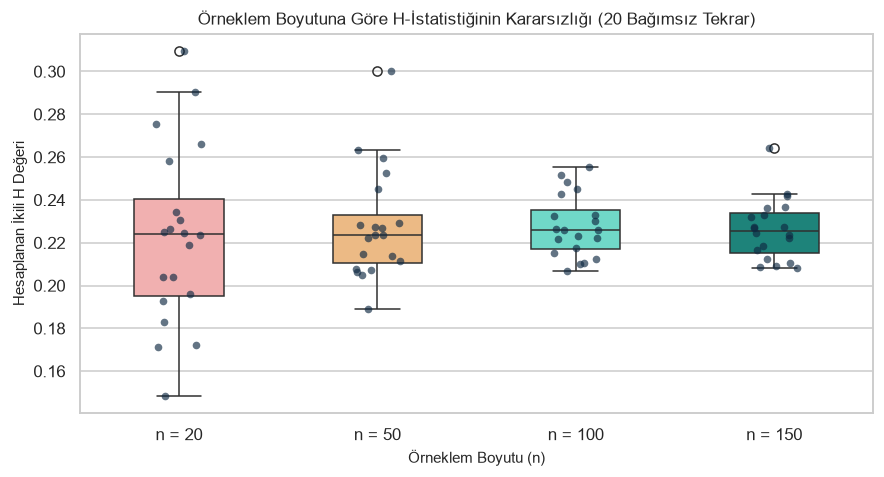

In [21]:
orneklem_boyutlari = [20, 50, 100, 150]
tekrar_sayisi = 20
kararsizlik_kayitlari = []

for n_boyut in orneklem_boyutlari:
    for tekrar in range(tekrar_sayisi):
        sonuc_n = h_istatistigi_ikili(
            rf_olasilik_fn,
            X_matris,
            j_kutle,
            k_derinlik,
            orneklem_boyutu=n_boyut,
            tohum=1000 + n_boyut * 100 + tekrar,
        )
        kararsizlik_kayitlari.append({
            "Örneklem Boyutu (n)": f"n = {n_boyut}",
            "n_sayisal": n_boyut,
            "İkili H (body_mass_g : bill_depth_mm)": sonuc_n["H"],
        })

df_kararsizlik = pd.DataFrame(kararsizlik_kayitlari)

plt.figure(figsize=(8.2, 4.5))
sns.boxplot(
    data=df_kararsizlik,
    x="Örneklem Boyutu (n)",
    y="İkili H (body_mass_g : bill_depth_mm)",
    palette=["#fca5a5", "#fdba74", "#5eead4", "#0d9488"],
    width=0.45,
)
sns.stripplot(
    data=df_kararsizlik,
    x="Örneklem Boyutu (n)",
    y="İkili H (body_mass_g : bill_depth_mm)",
    color="#0f2942",
    size=5,
    alpha=0.65,
    jitter=0.12,
)
plt.title("Örneklem Boyutuna Göre H-İstatistiğinin Kararsızlığı (20 Bağımsız Tekrar)")
plt.ylabel("Hesaplanan İkili H Değeri")
plt.tight_layout()
plt.show()

**Yorum:** H-istatistiğini hızlandırmak için tüm veri yerine rastgele $n$ satırlık bir alt örneklem seçtiğimizde **Monte Carlo örnekleme varyansı** ortaya çıkar. Grafikte görüldüğü gibi $n = 20$ gibi çok küçük bir örneklemde H tahmini çalıştırmadan çalıştırmaya geniş bir aralıkta savrulur (kutu boyu uzundur). Örneklem boyutu $n = 100$ ve $n = 150$ düzeyine çıktıkça kutu belirgin biçimde daralır ve tahmin kararlı hale gelir. Bu yüzden kitap, örnekleme kullanıldığında hesabın birkaç kez tekrarlanıp kararlılığın kontrol edilmesini tavsiye eder.

### H-İstatistiğinin Hesaplama Maliyeti Tablosu — Veri boyutu $n$ büyüdükçe ikili ($2n^2$) ve toplam ($3n^2$) H hesabı için gereken model tahmin çağrısı sayılarının incelenmesi.

In [22]:
n_degerleri = [20, 50, 100, 150, 500, 1_000, 5_000]
maliyet_df = pd.DataFrame({
    "Örneklem Boyutu (n)": n_degerleri,
    "İkili H Tahmin Çağrısı (2n²)": [2 * (n ** 2) for n in n_degerleri],
    "Toplam H Tahmin Çağrısı (3n²)": [3 * (n ** 2) for n in n_degerleri],
})
maliyet_df

,Örneklem Boyutu (n),İkili H Tahmin Çağrısı (2n²),Toplam H Tahmin Çağrısı (3n²)
0,20,800,1200
1,50,5000,7500
2,100,20000,30000
3,150,45000,67500
4,500,500000,750000
5,1000,2000000,3000000
6,5000,50000000,75000000


**Yorum:** Neden tüm veriyi kullanmak yerine $n = 150$ gibi bir örneklem seçmek zorunda kalıyoruz? Çünkü H-istatistiği $n$ veri noktasının her biri için tekrar $n$ nokta üzerinden kısmi bağımlılık ortalaması alır; yani maliyeti **$O(n^2)$** hızıyla karesel büyür. Tabloda görüldüğü gibi $n = 150$ için toplam H hesabı modelden `67.500` tahmin isterken, $n = 5.000$ olduğunda tek bir özellik için bile **75 milyon** tahmin çağrısı gerekir!

<a id="bolum-21-5"></a>
### 1.5 Normalize Edilmemiş $H^*_{jk}$ İstatistiği ve Küçük Paydada Sahte Etkileşim — Inglis vd. (2022) formülü ve küçük payda tuzağının gösterilmesi.

Bölüm 21.5'te vurgulanan çok önemli bir tuzak vardır: İki özellik modelin genel tahmininde **neredeyse hiçbir rol oynamasa bile** (toplam etkileri çok zayıfsa), aralarındaki o minicik etki saf çarpım biçimindeyse standart $H_{jk}$ formülünün paydası ($PD_{jk}$ varyansı) da payı kadar küçük olur ve oran **$H_{jk} \approx 1.0$** çıkar! Kullanıcı bunu görünce önemsiz iki özelliğin modelde dev bir etkileşim yarattığını sanabilir (**sahte / yanıltıcı etkileşim**).

Bunu önlemek için Inglis vd. (2022) ve Molnar, paydaya bölmek yerine yalnızca payın karekökünü alan **normalize edilmemiş H-istatistiğini** ($H^*_{jk}$) önerir:

$$H^{*}_{jk} = \sqrt{\sum_{i=1}^n\left[PD_{jk}\!\left(x_{j}^{(i)},x_k^{(i)}\right) - PD_j\!\left(x_j^{(i)}\right) - PD_k\!\left(x_{k}^{(i)}\right)\right]^2}$$

**Kelimelerle anlamı:** $H^*_{jk}$, etkileşimi "kendi küçük dünyasındaki pay" olarak değil, doğrudan **hedef değişkenin kendi biriminde (ölçeğinde)** ölçer. Böylece toplam etkisi ihmal edilebilir düzeyde olan özelliklerin $H^*_{jk}$ değeri de sıfıra yakın kalır.

**Ek örnek (kitapta yok)**

### Küçük Paydada Sahte Etkileşim Demosu — Güçlü etkileşim ile önemsiz gürültü etkileşiminin standart $H_{jk}$ ve normalize edilmemiş $H^*_{jk}$ altında karşılaştırılması.

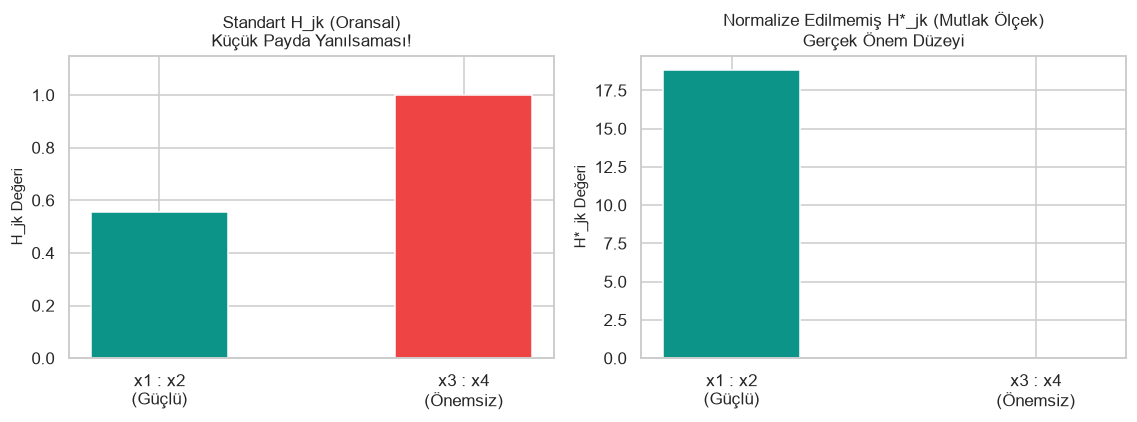

,Özellik Çifti,Payda Σ PD_jk²,Standart H_jk,Normalize Edilmemiş H*_jk
0,"x1 : x2 (Gerçek Güçlü Etkileşim, katsayı=5.0)",1148.895200,0.5556,18.8337
1,"x3 : x4 (Önemsiz Gürültü Çifti, katsayı=0.002)",0.000067,1.0000,0.0082


In [23]:
rng_sahte = np.random.default_rng(TOHUM)
X_sahte = rng_sahte.uniform(-1.0, 1.0, size=(150, 4))
X_sahte = X_sahte - X_sahte.mean(axis=0, keepdims=True)

# Model: x1 ve x2 güçlü etkileşimde (katsayı = 5.0), x3 ve x4 ise neredeyse etkisiz (katsayı = 0.002)
def sahte_etkilesim_modeli(Z: np.ndarray) -> np.ndarray:
    return 4.0 * Z[:, 0] + 5.0 * (Z[:, 0] * Z[:, 1]) + 0.002 * (Z[:, 2] * Z[:, 3])

gercek_cift = h_istatistigi_ikili(sahte_etkilesim_modeli, X_sahte, 0, 1, orneklem_boyutu=None)
sahte_cift = h_istatistigi_ikili(sahte_etkilesim_modeli, X_sahte, 2, 3, orneklem_boyutu=None)

sahte_df = pd.DataFrame([
    {
        "Özellik Çifti": "x1 : x2 (Gerçek Güçlü Etkileşim, katsayı=5.0)",
        "Payda Σ PD_jk²": round(gercek_cift["payda"], 4),
        "Standart H_jk": round(gercek_cift["H"], 4),
        "Normalize Edilmemiş H*_jk": round(gercek_cift["H_yildiz"], 4),
    },
    {
        "Özellik Çifti": "x3 : x4 (Önemsiz Gürültü Çifti, katsayı=0.002)",
        "Payda Σ PD_jk²": round(sahte_cift["payda"], 8),
        "Standart H_jk": round(sahte_cift["H"], 4),
        "Normalize Edilmemiş H*_jk": round(sahte_cift["H_yildiz"], 4),
    },
])

fig, eksenler = plt.subplots(1, 2, figsize=(10.5, 4.0))
cift_etiketleri = ["x1 : x2\n(Güçlü)", "x3 : x4\n(Önemsiz)"]

eksenler[0].bar(cift_etiketleri, [gercek_cift["H"], sahte_cift["H"]], color=["#0d9488", "#ef4444"], width=0.45)
eksenler[0].set_title("Standart H_jk (Oransal)\nKüçük Payda Yanılsaması!")
eksenler[0].set_ylabel("H_jk Değeri")
eksenler[0].set_ylim(0, 1.15)

eksenler[1].bar(cift_etiketleri, [gercek_cift["H_yildiz"], sahte_cift["H_yildiz"]], color=["#0d9488", "#64748b"], width=0.45)
eksenler[1].set_title("Normalize Edilmemiş H*_jk (Mutlak Ölçek)\nGerçek Önem Düzeyi")
eksenler[1].set_ylabel("H*_jk Değeri")

plt.tight_layout()
plt.show()

sahte_df

**Yorum:** Sonuç çarpıcıdır! $x_3$ ve $x_4$ özelliklerinin katsayısı `0.002` (yani model çıktısını binde iki kadar bile değiştirmiyor) olmasına rağmen, tekil etkileri sıfır olduğu için paydası `0.000067` gibi çok küçük bir sayıya düşmüş ve standart **$H_{34} = 1.0000$** çıkarak sanki $x_1 : x_2$ çiftinden (`H_12 = 0.5556`) bile daha güçlü bir etkileşim varmış gibi **sahte alarm** üretmiştir! Sağdaki **normalize edilmemiş $H^*_{jk}$** grafiği ise gerçeği anında gösterir: $x_1 : x_2$ etkileşimi tahmin ölçeğinde büyük bir etkiye (`H*_12 = 18.8337`) sahipken, $x_3 : x_4$ çiftinin gerçek etkisi sıfıra yakındır (`H*_34 = 0.0082`).

<a id="bolum-22"></a>
<a id="bolum-22-1"></a>
## Bölüm 22: Fonksiyonel Ayrıştırma (Functional Decomposition)

Gözetimli bir makine öğrenmesi modeli, $p$ adet özelliği girdi alıp tek bir tahmin üreten yüksek boyutlu bir fonksiyon ($\hat{f}: \mathbb{R}^p \mapsto \mathbb{R}$) olarak görülebilir. **Fonksiyonel ayrıştırma**, bu karmaşık kara kutu fonksiyonunu görselleştirilebilen küçük ve anlaşılır parçalara — bir sabit terime, tekil ana etkilere ve etkileşim etkilerine — ayırma ilkesidir.

### 2.1 İki Boyutlu Örnek Fonksiyonun Tanımlanması ve Tahmin Yüzeyi — Kitaptaki $\hat{f}(x_1, x_2) = 2 + e^{x_1} - x_2 + x_1 \cdot x_2$ fonksiyonunun ısı haritası ve eşyükselti eğrilerinin çizdirilmesi.

Kitaptaki temel örneği ele alalım ($x_1, x_2 \in [-1, 1]$):

$$\hat{f}(x_1, x_2) = 2 + e^{x_1} - x_2 + x_1 \cdot x_2$$

Amacımız bu iki boyutlu tahmin yüzeyini dört anlamlı bileşenin toplamı olarak ifade etmektir:

$$\hat{f}(x_1, x_2) = \hat{f}_0 + \hat{f}_1(x_1) + \hat{f}_2(x_2) + \hat{f}_{1,2}(x_1, x_2)$$

**Kelimelerle anlamı:** $\hat{f}_0$ tüm tahminlerin ortak başlangıç ortalaması (kesişim/sabit terim), $\hat{f}_1(x_1)$ yalnızca birinci özelliğin tekil ana etkisi, $\hat{f}_2(x_2)$ yalnızca ikinci özelliğin tekil ana etkisi ve $\hat{f}_{1,2}(x_1, x_2)$ ise iki özelliğin birlikte yarattığı saf etkileşim yüzeyidir.

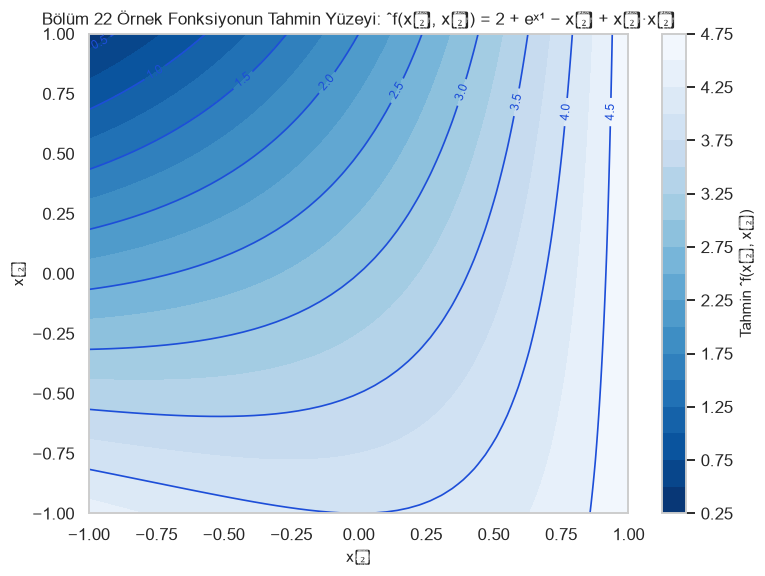

In [24]:
def f_bolum22(x1: np.ndarray, x2: np.ndarray) -> np.ndarray:
    '''Molnar Bölüm 22 açılış örneği: f(x1, x2) = 2 + exp(x1) - x2 + x1 * x2.'''
    return 2.0 + np.exp(x1) - x2 + (x1 * x2)


x1_izgara = np.linspace(-1.0, 1.0, 50)
x2_izgara = np.linspace(-1.0, 1.0, 50)
X1_g, X2_g = np.meshgrid(x1_izgara, x2_izgara)
Y_yuzey = f_bolum22(X1_g, X2_g)

plt.figure(figsize=(7.2, 5.4))
dolgu = plt.contourf(X1_g, X2_g, Y_yuzey, levels=20, cmap="Blues_r")
cizgi = plt.contour(X1_g, X2_g, Y_yuzey, levels=9, colors="#1d4ed8", linewidths=1.1)
plt.clabel(cizgi, inline=True, fontsize=8, fmt="%.1f")
plt.colorbar(dolgu, label="Tahmin ˆf(x₁, x₂)")
plt.title("Bölüm 22 Örnek Fonksiyonun Tahmin Yüzeyi: ˆf(x₁, x₂) = 2 + eˣ¹ − x₂ + x₁·x₂")
plt.xlabel("x₁")
plt.ylabel("x₂")
plt.tight_layout()
plt.show()

**Yorum:** Isı haritasında açık mavi bölgeler yüksek tahminleri, koyu lacivert bölgeler ise düşük tahminleri gösterir. Fonksiyon $x_1$ büyük ve $x_2$ küçükken (sağ alt köşe) en büyük değerini alır. Eşyükselti (kontur) eğrilerinin düz paralel çizgiler yerine bükülerek yelpaze gibi açılması, $x_1$'i artırmanın etkisinin $x_2$'nin o anki değerine bağlı olduğunu — yani fonksiyonun içinde bir **etkileşim** bulunduğunu — doğrudan gösterir.

### Fonksiyonun Bileşenlere Ayrıştırılması ve Doğrulanması — $\hat{f}_0 \approx 3{,}18$, $\hat{f}_1$, $\hat{f}_2$ ve $\hat{f}_{1,2}$ bileşenlerinin hesaplanması, çizdirilmesi ve toplamlarının $\hat{f}$'ye eşit olduğunun kanıtlanması.

Kesişim (sabit) terimi ˆf₀ = 2 + sinh(1) = 3.175201 (kitaptaki yuvarlatılmış değer: 3.18 ✓)
Maksimum |ˆf(x₁, x₂) − (ˆf₀ + ˆf₁ + ˆf₂ + ˆf₁₂)| hatası = 1.78e-15 ✓


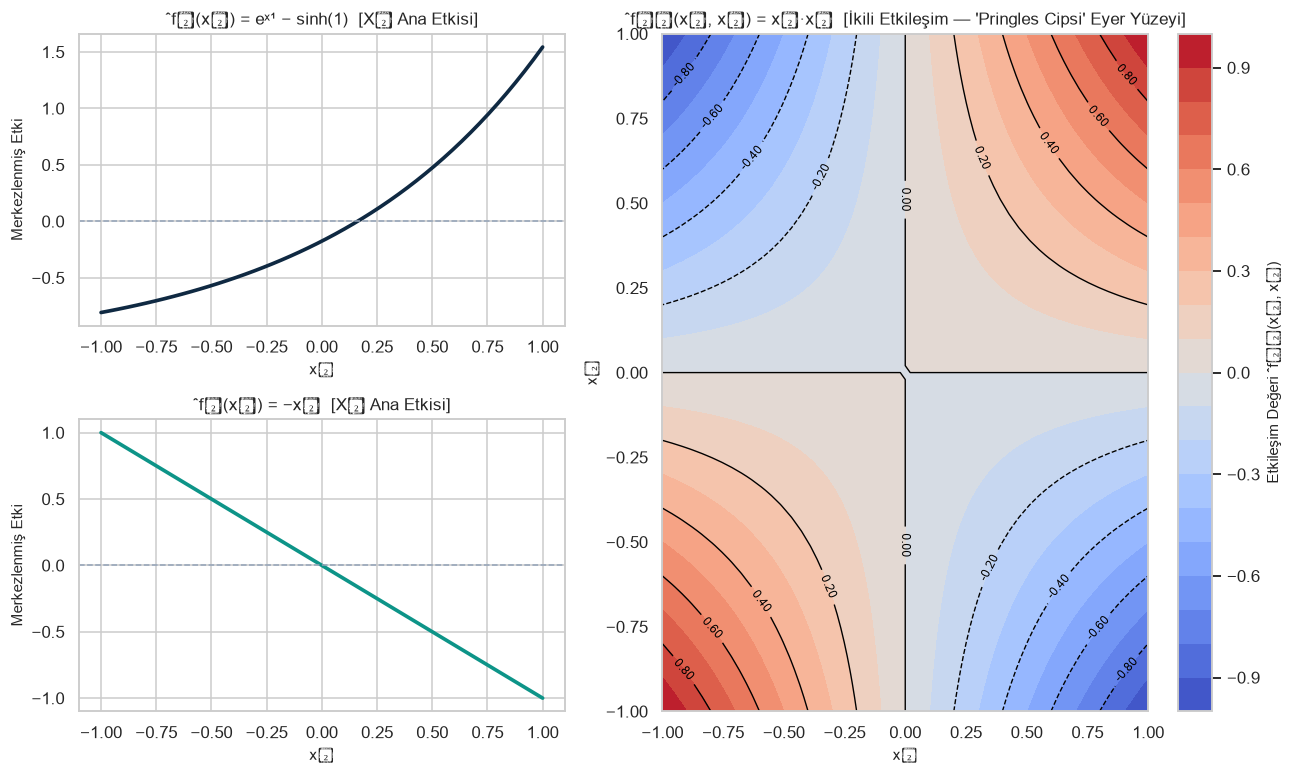

In [25]:
# [-1, 1] üzerinde e^x1'in integrali e^1 - e^(-1) = 2*sinh(1), ortalaması ise (1/2)*2*sinh(1) = sinh(1)'dir
sinh_1 = float(np.sinh(1.0))
f0_sabit = 2.0 + sinh_1                      # ≈ 3.175201 (kitapta ≈ 3.18)
f1_egri = np.exp(x1_izgara) - sinh_1         # X1 ana etkisi (sıfır ortalamalı üstel eğri)
f2_egri = -x2_izgara                         # X2 ana etkisi (sıfır ortalamalı negatif doğrusal)
F12_yuzey = X1_g * X2_g                      # X1 ve X2 saf etkileşim yüzeyi

# 2 boyutlu ızgara üzerinde tüm bileşenlerin toplamını oluşturup gerçek fonksiyonla karşılaştır
Y_yeniden = f0_sabit + np.exp(X1_g) - sinh_1 + (-X2_g) + F12_yuzey
maks_toplam_hatasi = float(np.max(np.abs(Y_yuzey - Y_yeniden)))

assert abs(round(f0_sabit, 2) - 3.18) < 1e-9, f"f0 ≈ 3.18 olmalıydı, bulunan: {f0_sabit}"
assert maks_toplam_hatasi < 1e-14, f"Bileşen toplamı f'ye eşit değil! Maks hata: {maks_toplam_hatasi}"

print(f"Kesişim (sabit) terimi ˆf₀ = 2 + sinh(1) = {f0_sabit:.6f} (kitaptaki yuvarlatılmış değer: {f0_sabit:.2f} ✓)")
print(f"Maksimum |ˆf(x₁, x₂) − (ˆf₀ + ˆf₁ + ˆf₂ + ˆf₁₂)| hatası = {maks_toplam_hatasi:.2e} ✓")

fig = plt.figure(figsize=(12, 7.2))
gs = fig.add_gridspec(2, 2, width_ratios=[1.0, 1.25])

ax_f1 = fig.add_subplot(gs[0, 0])
ax_f1.plot(x1_izgara, f1_egri, color="#0f2942", linewidth=2.4)
ax_f1.axhline(0, color="#94a3b8", linestyle="--", linewidth=1)
ax_f1.set_title("ˆf₁(x₁) = eˣ¹ − sinh(1)  [X₁ Ana Etkisi]")
ax_f1.set_xlabel("x₁")
ax_f1.set_ylabel("Merkezlenmiş Etki")

ax_f2 = fig.add_subplot(gs[1, 0])
ax_f2.plot(x2_izgara, f2_egri, color="#0d9488", linewidth=2.4)
ax_f2.axhline(0, color="#94a3b8", linestyle="--", linewidth=1)
ax_f2.set_title("ˆf₂(x₂) = −x₂  [X₂ Ana Etkisi]")
ax_f2.set_xlabel("x₂")
ax_f2.set_ylabel("Merkezlenmiş Etki")

ax_f12 = fig.add_subplot(gs[:, 1])
im12 = ax_f12.contourf(X1_g, X2_g, F12_yuzey, levels=21, cmap="coolwarm")
ct12 = ax_f12.contour(X1_g, X2_g, F12_yuzey, levels=9, colors="black", linewidths=0.9)
ax_f12.clabel(ct12, inline=True, fontsize=8, fmt="%.2f")
fig.colorbar(im12, ax=ax_f12, label="Etkileşim Değeri ˆf₁₂(x₁, x₂)")
ax_f12.set_title("ˆf₁₂(x₁, x₂) = x₁·x₂  [İkili Etkileşim — 'Pringles Cipsi' Eyer Yüzeyi]")
ax_f12.set_xlabel("x₁")
ax_f12.set_ylabel("x₂")

plt.tight_layout()
plt.show()

**Yorum:** Karmaşık görünen iki boyutlu yüzey üç tertemiz parçaya ayrıldı! Neden sabit terim $2$ değil de $\hat{f}_0 = 2 + \sinh(1) \approx 3{,}18$ çıktı? Çünkü $[-1, 1]$ aralığında $e^{x_1}$ teriminin ortalaması sıfır değildir ($\sinh(1) \approx 1{,}1752$'dir); ana etki eğrisi $\hat{f}_1(x_1)$'in sıfır etrafında dengeli (merkezlenmiş) olabilmesi için bu ortalama sabit terime aktarılmıştır. Sol üstte $x_1$'in üstel artışını, sol altta $x_2$'nin negatif doğrusal etkisini, sağda ise Molnar'ın **"Pringles cipsine"** benzettiği hiperbolik paraboloid (eyer) biçimli saf çarpım etkileşimini ($x_1 \cdot x_2$) görüyoruz: aynı işaretli köşelerde ($+,+$ ve $-,-$) tahmin yukarı kıvrılırken zıt işaretli köşelerde aşağı kıvrılmaktadır.

<a id="bolum-22-2"></a>
### 2.2 Genel Ayrıştırma Formülü ve Benzersizlik Problemi — $2^p$ bileşen patlaması ve ek kısıtlar olmadığında bileşenlerin neden tekil olmadığının açıklanması.

Genel olarak $p$ özellikli bir modelde, $\{1, \ldots, p\}$ kümesinin tüm olası $S$ alt kümeleri üzerinden ayrıştırma yazılır:

$$\hat{f}(\mathbf{x}) = \sum_{S\subseteq\{1,\ldots,p\}} \hat{f}_S(\mathbf{x}_S)$$

**Kelimelerle anlamı:** Boş küme ($S = \emptyset$) sabit terimi, tek elemanlı kümeler ($|S| = 1$) ana etkileri, iki veya daha fazla elemanlı kümeler ($|S| \geq 2$) ise etkileşimleri temsil eder. Toplam bileşen sayısı $\sum_{i=0}^p \binom{p}{i} = 2^p$ kadardır; örneğin yalnızca $p = 10$ özellik için bile $2^{10} = 1.024$ bileşen ortaya çıkar!

Üstelik sadece *"bileşenlerin toplamı $\hat{f}$'yi versin"* demek yeterli değildir; ek kurallar (aksiyomlar) koymazsak **sonsuz sayıda farklı ayrıştırma** üretebiliriz! Etkiyi dilediğimiz gibi ana etkilerden alıp etkileşim teriminin içine saklayabiliriz.

**Ek örnek (kitapta yok)**

### Etkiyi Ana Etkiden Etkileşime Kaydırma Gösterimi — $\hat{f}(x_1, x_2) = x_1 \cdot x_2$ fonksiyonunda toplam değişmezken farklı $\alpha$ kaydırma değerleriyle bileşenlerin tamamen değiştiğinin görselleştirilmesi.

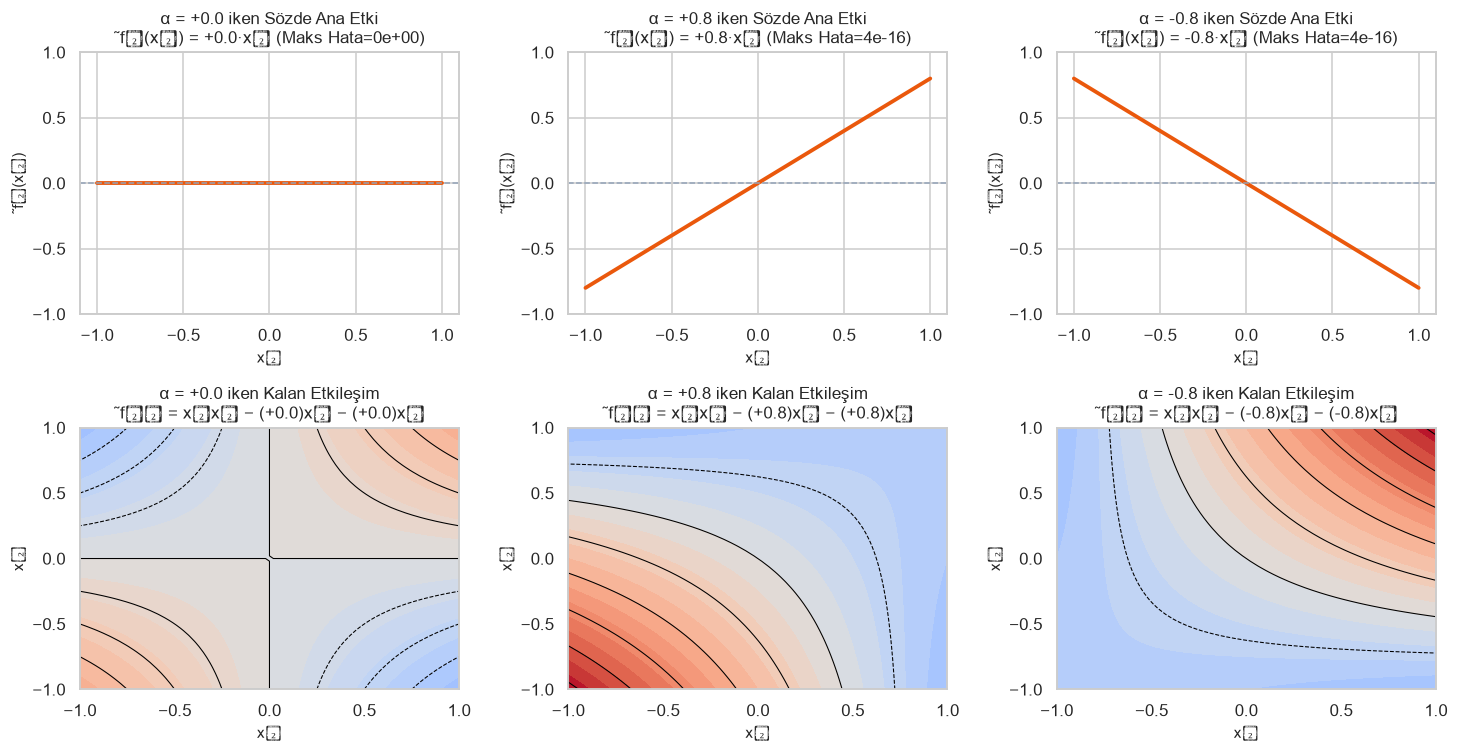

In [26]:
# f(x1, x2) = x1 * x2 fonksiyonunu keyfi bir alpha parametresiyle sonsuz farklı biçimde yazabiliriz:
# f0 = 0,  f1_tilde(x1) = alpha * x1,  f2_tilde(x2) = alpha * x2,  f12_tilde(x1, x2) = x1*x2 - alpha*x1 - alpha*x2
alfa_degerleri = [0.0, 0.8, -0.8]
gercek_carpim = X1_g * X2_g

fig, eksenler = plt.subplots(2, 3, figsize=(13.5, 7.0))

for sutun_idx, alfa in enumerate(alfa_degerleri):
    f1_kaydirilmis = alfa * x1_izgara
    F12_kaydirilmis = (X1_g * X2_g) - (alfa * X1_g) - (alfa * X2_g)
    toplam_kontrol = (alfa * X1_g) + (alfa * X2_g) + F12_kaydirilmis
    fark = float(np.max(np.abs(gercek_carpim - toplam_kontrol)))
    assert fark < 1e-15, "Kaydırılmış ayrıştırma toplamı bozuldu!"

    # Üst satır: sözde X1 ana etkisi
    eksenler[0, sutun_idx].plot(x1_izgara, f1_kaydirilmis, color="#ea580c", linewidth=2.5)
    eksenler[0, sutun_idx].axhline(0, color="#94a3b8", linestyle="--", linewidth=1)
    eksenler[0, sutun_idx].set_ylim(-1.0, 1.0)
    eksenler[0, sutun_idx].set_title(f"α = {alfa:+.1f} iken Sözde Ana Etki\n˜f₁(x₁) = {alfa:+.1f}·x₁ (Maks Hata={fark:.0e})")
    eksenler[0, sutun_idx].set_xlabel("x₁")
    eksenler[0, sutun_idx].set_ylabel("˜f₁(x₁)")

    # Alt satır: geriye kalan etkileşim yüzeyi
    im = eksenler[1, sutun_idx].contourf(X1_g, X2_g, F12_kaydirilmis, levels=17, cmap="coolwarm", vmin=-2.6, vmax=2.6)
    eksenler[1, sutun_idx].contour(X1_g, X2_g, F12_kaydirilmis, levels=7, colors="black", linewidths=0.7)
    eksenler[1, sutun_idx].set_title(f"α = {alfa:+.1f} iken Kalan Etkileşim\n˜f₁₂ = x₁x₂ − ({alfa:+.1f})x₁ − ({alfa:+.1f})x₂")
    eksenler[1, sutun_idx].set_xlabel("x₁")
    eksenler[1, sutun_idx].set_ylabel("x₂")

plt.tight_layout()
plt.show()

**Yorum:** Üç sütunun üçünde de bileşenleri topladığımızda virgülden sonraki 15. basamağa kadar **aynı $x_1 \cdot x_2$ fonksiyonunu** elde ediyoruz! Fakat $\alpha = 0$ seçtiğimizde "$x_1$'in hiç ana etkisi yok" derken, $\alpha = +0{,}8$ seçtiğimizde "$x_1$ güçlü pozitif etkiye sahip", $\alpha = -0{,}8$ seçtiğimizde ise "$x_1$ güçlü negatif etkiye sahip" demiş oluyoruz (çünkü uydurduğumuz ana etkiyi alttaki etkileşim teriminden geri çıkarıyoruz). Kitaptaki "sahip olduğunuz ayakkabı sayısı" örneğinin gösterdiği gibi, keyfiliği önleyip **benzersiz (tekil)** ve dürüst bir ayrıştırma elde etmek için matematiksel aksiyomlara ihtiyacımız vardır.

<a id="bolum-22-3"></a>
### 2.3 Fonksiyonel ANOVA (fANOVA) ve Hooker (2004) Aksiyomları — Tekdüze dağılım altında özyinelemeli bileşen tanımı ve sıfır ortalama, diklik, varyans ayrıştırması aksiyomları.

Hooker (2004), benzersizlik problemini çözmek için özelliklerin kendi tanım aralıklarında bağımsız ve **tekdüze (uniform)** dağıldığı varsayımı altında her bir $\hat{f}_S$ bileşenini özyinelemeli olarak tanımlar:

$$\hat{f}_S(\mathbf{x}_S) = \int_{X_{-S}} \left( \hat{f}(\mathbf{x}) - \sum_{V \subset S} \hat{f}_V(\mathbf{x}_V)\right) d \mathbb{P}(X_{-S})$$

**Kelimelerle anlamı:** Bir bileşeni bulmak için kümenin dışındaki özellikler ($X_{-S}$) üzerinden ortalama (integral) alırız ve daha alt mertebedeki tüm bileşenleri ($\hat{f}_0$, ana etkiler vb.) çıkarırız. Bu tanım bileşenleri **tekil** kılar ve üç altın aksiyomu garanti eder:

1. **Sıfır Ortalama (Zero Means):** Sabit terim hariç her bileşenin ortalaması sıfırdır ($S \neq \emptyset$ için):

$$\int \hat{f}_S(\mathbf{x}_S)\, d\mathbb{P}(X_S) = 0$$

2. **Diklik / Ortogonallik (Orthogonality):** Farklı iki bileşen ($S \neq V$) birbiriyle hiç bilgi paylaşmaz; çarpımlarının integrali sıfırdır:

$$\int \hat{f}_S(\mathbf{x}_S)\,\hat{f}_V(\mathbf{x}_V)\, d\mathbb{P}(X) = 0$$

3. **Varyans Ayrıştırması (Variance Decomposition):** Fonksiyonun toplam varyansı, tüm bileşenlerin varyansları toplamına tam olarak eşittir:

$$\sigma^2(\hat{f}) = \sum_{S \subseteq \{1,\ldots,p\},\, S \neq \emptyset} \sigma^2\!\left(\hat{f}_S\right)$$

**Ek örnek (kitapta yok)**

### $[0, 2]$ Aralığında $f(x_1, x_2) = x_1 \cdot x_2$ İçin fANOVA Hesabı ve Üç Aksiyomun Sayısal Sınanması — Kuramsal bileşenlerin ($\hat{f}_0=1$, $\hat{f}_1=x_1-1$, $\hat{f}_2=x_2-1$, $\hat{f}_{1,2}=(x_1-1)(x_2-1)$) ve üç aksiyomun `numpy` ile doğrulanması.

In [27]:
def fanova_2b_yamuk(f_matris: np.ndarray, x1_eksen: np.ndarray, x2_eksen: np.ndarray) -> dict:
    '''2 boyutlu [a,b]x[c,d] tekdüze ızgarada yamuk (trapezoid) ağırlıklarıyla fANOVA bileşenlerini ve aksiyomları hesaplar.'''
    # Tekdüze olasılık yoğunluğu altında yamuk kuralı entegrasyon ağırlıkları (toplamı = 1)
    w1 = np.ones_like(x1_eksen, dtype=float)
    w1[0] = 0.5
    w1[-1] = 0.5
    w1 = w1 / w1.sum()

    w2 = np.ones_like(x2_eksen, dtype=float)
    w2[0] = 0.5
    w2[-1] = 0.5
    w2 = w2 / w2.sum()

    # f_matris boyutu: (len(x2), len(x1)) -> satırlar x2, sütunlar x1
    W_2b = np.outer(w2, w1)

    f0 = float(np.sum(W_2b * f_matris))
    # X1 ana etkisi: X2 (satırlar, eksen=0) üzerinden integral al ve f0 çıkar
    f1 = np.sum(w2[:, None] * f_matris, axis=0) - f0
    # X2 ana etkisi: X1 (sütunlar, eksen=1) üzerinden integral al ve f0 çıkar
    f2 = np.sum(w1[None, :] * f_matris, axis=1) - f0
    # İkili etkileşim: f(x1, x2) - f0 - f1(x1) - f2(x2)
    F1_2b = np.broadcast_to(f1[None, :], f_matris.shape)
    F2_2b = np.broadcast_to(f2[:, None], f_matris.shape)
    f12 = f_matris - f0 - F1_2b - F2_2b

    # 1) Sıfır Ortalama sınamaları
    ort_f1 = float(np.sum(w1 * f1))
    ort_f2 = float(np.sum(w2 * f2))
    ort_f12 = float(np.sum(W_2b * f12))

    # 2) Diklik (Ortogonallik) iç çarpım sınamaları
    ic_f1_f2 = float(np.sum(W_2b * F1_2b * F2_2b))
    ic_f1_f12 = float(np.sum(W_2b * F1_2b * f12))
    ic_f2_f12 = float(np.sum(W_2b * F2_2b * f12))

    # 3) Varyans Ayrıştırması sınaması
    var_toplam = float(np.sum(W_2b * ((f_matris - f0) ** 2)))
    var_f1 = float(np.sum(W_2b * (F1_2b ** 2)))
    var_f2 = float(np.sum(W_2b * (F2_2b ** 2)))
    var_f12 = float(np.sum(W_2b * (f12 ** 2)))
    var_bilesen_toplami = var_f1 + var_f2 + var_f12

    return {
        "f0": f0, "f1": f1, "f2": f2, "f12": f12,
        "ortalamalar": (ort_f1, ort_f2, ort_f12),
        "diklikler": (ic_f1_f2, ic_f1_f12, ic_f2_f12),
        "varyanslar": (var_toplam, var_f1, var_f2, var_f12, var_bilesen_toplami),
    }


x1_fanova = np.linspace(0.0, 2.0, 81)
x2_fanova = np.linspace(0.0, 2.0, 81)
X1_fa, X2_fa = np.meshgrid(x1_fanova, x2_fanova)
F_fa = X1_fa * X2_fa

fa_sonuc = fanova_2b_yamuk(F_fa, x1_fanova, x2_fanova)

# Analitik beklentilerle karşılaştırma: f0=1, f1=x1-1, f2=x2-1, f12=(x1-1)*(x2-1)
assert abs(fa_sonuc["f0"] - 1.0) < 1e-12
assert np.max(np.abs(fa_sonuc["f1"] - (x1_fanova - 1.0))) < 1e-12
assert np.max(np.abs(fa_sonuc["f2"] - (x2_fanova - 1.0))) < 1e-12
assert np.max(np.abs(fa_sonuc["f12"] - (X1_fa - 1.0) * (X2_fa - 1.0))) < 1e-12

# Üç aksiyom için sayısal tolerans sınaması
maks_ort_hata = max(abs(v) for v in fa_sonuc["ortalamalar"])
maks_dik_hata = max(abs(v) for v in fa_sonuc["diklikler"])
var_toplam, var_f1, var_f2, var_f12, var_bilesen_toplami = fa_sonuc["varyanslar"]
var_fark = abs(var_toplam - var_bilesen_toplami)

assert maks_ort_hata < 1e-12, "Sıfır ortalama aksiyomu başarısız!"
assert maks_dik_hata < 1e-12, "Diklik aksiyomu başarısız!"
assert var_fark < 1e-12, "Varyans ayrıştırması aksiyomu başarısız!"

print(f"✓ Kuramsal Bileşen Eşleşmesi : ˆf₀ = {fa_sonuc['f0']:.4f} (beklenen: 1.0000), ˆf₁ = x₁−1, ˆf₂ = x₂−1, ˆf₁₂ = (x₁−1)(x₂−1)")
print(f"✓ Aksiyom 1 — Sıfır Ortalama : E[ˆf₁]={fa_sonuc['ortalamalar'][0]:.2e}, E[ˆf₂]={fa_sonuc['ortalamalar'][1]:.2e}, E[ˆf₁₂]={fa_sonuc['ortalamalar'][2]:.2e}")
print(f"✓ Aksiyom 2 — Diklik         : <ˆf₁,ˆf₂>={fa_sonuc['diklikler'][0]:.2e}, <ˆf₁,ˆf₁₂>={fa_sonuc['diklikler'][1]:.2e}, <ˆf₂,ˆf₁₂>={fa_sonuc['diklikler'][2]:.2e}")
print(
    f"✓ Aksiyom 3 — Varyans Payı   : σ²(ˆf) = {var_toplam:.6f}  |  "
    f"σ²(ˆf₁)+σ²(ˆf₂)+σ²(ˆf₁₂) = {var_f1:.4f} + {var_f2:.4f} + {var_f12:.4f} = {var_bilesen_toplami:.6f} (Fark={var_fark:.2e})"
)

✓ Kuramsal Bileşen Eşleşmesi : ˆf₀ = 1.0000 (beklenen: 1.0000), ˆf₁ = x₁−1, ˆf₂ = x₂−1, ˆf₁₂ = (x₁−1)(x₂−1)
✓ Aksiyom 1 — Sıfır Ortalama : E[ˆf₁]=-9.02e-17, E[ˆf₂]=-4.16e-17, E[ˆf₁₂]=5.62e-17
✓ Aksiyom 2 — Diklik         : <ˆf₁,ˆf₂>=4.34e-19, <ˆf₁,ˆf₁₂>=1.39e-17, <ˆf₂,ˆf₁₂>=-2.11e-17
✓ Aksiyom 3 — Varyans Payı   : σ²(ˆf) = 0.778056  |  σ²(ˆf₁)+σ²(ˆf₂)+σ²(ˆf₁₂) = 0.3334 + 0.3334 + 0.1112 = 0.778056 (Fark=1.11e-16)


**Ek örnek (kitapta yok)**

### $[0, 2]$ Üzerinde fANOVA Bileşenlerinin Görselleştirilmesi — Pozitif tanım aralığında $x_1 \cdot x_2$ fonksiyonunun sıfırdan farklı ana etkilerinin ve merkezlenmiş etkileşim yüzeyinin çizdirilmesi.

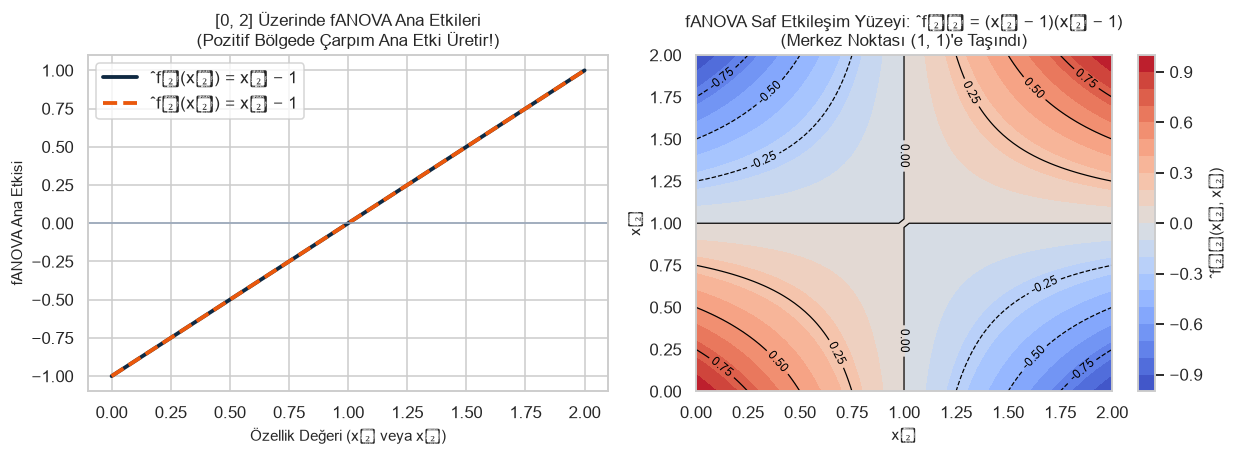

In [28]:
fig, eksenler = plt.subplots(1, 2, figsize=(11.5, 4.3))

eksenler[0].plot(x1_fanova, fa_sonuc["f1"], label="ˆf₁(x₁) = x₁ − 1", color="#0f2942", linewidth=2.5)
eksenler[0].plot(x2_fanova, fa_sonuc["f2"], label="ˆf₂(x₂) = x₂ − 1", color="#ea580c", linestyle="--", linewidth=2.5)
eksenler[0].axhline(0, color="#94a3b8", linewidth=1)
eksenler[0].set_title("[0, 2] Üzerinde fANOVA Ana Etkileri\n(Pozitif Bölgede Çarpım Ana Etki Üretir!)")
eksenler[0].set_xlabel("Özellik Değeri (x₁ veya x₂)")
eksenler[0].set_ylabel("fANOVA Ana Etkisi")
eksenler[0].legend()

im_fa = eksenler[1].contourf(X1_fa, X2_fa, fa_sonuc["f12"], levels=19, cmap="coolwarm")
ct_fa = eksenler[1].contour(X1_fa, X2_fa, fa_sonuc["f12"], levels=7, colors="black", linewidths=0.8)
eksenler[1].clabel(ct_fa, inline=True, fontsize=8, fmt="%.2f")
fig.colorbar(im_fa, ax=eksenler[1], label="ˆf₁₂(x₁, x₂)")
eksenler[1].set_title("fANOVA Saf Etkileşim Yüzeyi: ˆf₁₂ = (x₁ − 1)(x₂ − 1)\n(Merkez Noktası (1, 1)'e Taşındı)")
eksenler[1].set_xlabel("x₁")
eksenler[1].set_ylabel("x₂")

plt.tight_layout()
plt.show()

**Yorum:** Bu sonuç Bölüm 22.1'de Molnar'ın sorduğu kritik soruyu aydınlatır: *"Formüle çıplak gözle bakınca $f(x_1, x_2) = x_1 \cdot x_2$ içinde hiç tekil terim yokmuş gibi durur; ama $x_1, x_2 \in [0, 2]$ gibi pozitif bir aralıktaysak $x_1$'i artırmak her zaman tahmini büyütür!"* Gerçekten de fANOVA hesabı, $[0, 2]$ aralığında $x_2$'nin ortalaması $1$ olduğu için $\hat{f}_1(x_1) = x_1 - 1$ ve $\hat{f}_2(x_2) = x_2 - 1$ şeklinde **güçlü pozitif doğrusal ana etkiler** bulur! Üstelik varyans ayrıştırmasına bakarsak toplam varyansın (`0.7778` $\approx 7/9$) büyük kısmı ana etkilerden (`1/3 + 1/3 = 0.6667`), yalnızca yedide biri (`1/9 ≈ 0.1111`) saf etkileşimden gelmektedir.

<a id="bolum-22-4"></a>
### 2.4 Birikimli Yerel Etkiler (ALE) ve Kısmi Bağımlılık (PDP) — İlişkili (korelasyonlu) özelliklerde ekstrapolasyon problemi ve sözde diklik (pseudo-orthogonality).

Hem Kısmi Bağımlılık (PDP) hem de standart fANOVA, bir özelliğin etkisini ölçerken diğer özellikleri veri genelinde bağımsızca karıştırır. Özellikler güçlü biçimde **korelasyonluysa** (örneğin bir evin oda sayısı ile metrekaresi birlikte artıyorsa), "10 odalı ama 25 metrekare ev" gibi gerçek hayatta **var olmayan imkânsız kombinasyonlarda** modelden tahmin istenir (**dışdeğerleme / ekstrapolasyon**).

Apley ve Zhu (2020) tarafından geliştirilen **Birikimli Yerel Etkiler (Accumulated Local Effects - ALE)** bu sorunu kökten çözer:
- Özelliği küçük komşu aralıklara ($z_{k-1}, z_k]$ böler ve **yalnızca o aralıkta gerçekten gözlemlenen veri noktalarını** kullanarak özelliğin alt ve üst uçtaki tahmin farkını ($\hat{f}(z_k, x_{-j}) - \hat{f}(z_{k-1}, x_{-j})$) hesaplar, sonra bu yerel farkları biriktirip ortalamasını sıfırlar:

$$\hat{f}_{ALE, j}(x) = \sum_{k=1}^{k_j(x)} \frac{1}{n_j(k)} \sum_{i:\, x_j^{(i)} \in N_j(k)} \left[\hat{f}\!\left(z_{k,j}, \mathbf{x}_{-j}^{(i)}\right) - \hat{f}\!\left(z_{k-1,j}, \mathbf{x}_{-j}^{(i)}\right)\right] - \text{sabit}$$

**Kelimelerle anlamı:** ALE, veri olmayan boş bölgelere hiç adım atmaz; yalnızca gerçek gözlemlerin bulunduğu komşulukta "bu özelliği bir adım artırırsam tahmin ne kadar değişiyor?" sorusunu sorar ve bu küçük adımları uç uca ekler. Ayrıca ALE operatörü $H_S$, **sözde diklik (pseudo-orthogonality)** özelliğine sahiptir: aynı ALE operatörü iki kez uygulanırsa sonuç değişmez ($H_S(H_S(\hat{f})) = \hat{f}_{ALE,S}$), farklı bir $U \neq S$ alt kümesinin ALE operatörü uygulanırsa sonuç **sıfır** olur ($H_U(H_S(\hat{f})) = 0$). PDP ise alt etkileri içinde barındırdığı için geçerli bir fonksiyonel ayrıştırma **değildir**.

### 1 Boyutlu ve 2 Boyutlu ALE Fonksiyonlarının Sıfırdan Kodlanması — Yerel farkların birikimli toplamı ve merkezlenmesiyle saf `numpy` 1B/2B ALE algoritmalarının yazılması.

In [29]:
def ale_1b(tahmin_fn, X: np.ndarray, j: int, kutu_sayisi: int = 20) -> tuple:
    '''j. özellik için 1 boyutlu merkezlenmiş Birikimli Yerel Etki (1B ALE) eğrisini hesaplar.'''
    X = np.asarray(X, dtype=float)
    x_j = X[:, j]

    # Eşit yüzdelikli (quantile) aralık sınırları oluştur; tekrar eden sınırları tekilleştir
    sinirlar = np.unique(np.quantile(x_j, np.linspace(0.0, 1.0, kutu_sayisi + 1)))
    if len(sinirlar) < 2:
        return np.array([x_j.mean()]), np.array([0.0]), sinirlar

    m_kutu = len(sinirlar) - 1
    # Her gözlemin hangi kutuya düştüğünü bul (1 .. m_kutu)
    kutu_indis = np.clip(np.searchsorted(sinirlar, x_j, side="right"), 1, m_kutu)

    yerel_farklar = np.zeros(m_kutu, dtype=float)
    kutu_sayilari = np.zeros(m_kutu, dtype=int)

    for k in range(1, m_kutu + 1):
        maske = kutu_indis == k
        n_k = int(np.sum(maske))
        kutu_sayilari[k - 1] = n_k
        if n_k > 0:
            X_alt = X[maske].copy()
            X_ust = X[maske].copy()
            X_alt[:, j] = sinirlar[k - 1]
            X_ust[:, j] = sinirlar[k]
            yerel_farklar[k - 1] = float(np.mean(tahmin_fn(X_ust) - tahmin_fn(X_alt)))
        elif k > 1:
            yerel_farklar[k - 1] = yerel_farklar[k - 2]

    # Sınır noktalarında birikimli etki (alt sınır 0'dan başlar)
    ale_sinir = np.concatenate([[0.0], np.cumsum(yerel_farklar)])
    # Kutu orta noktalarındaki değerlerle veri ağırlıklı sıfır ortalama merkezlemesi
    kutu_orta_ale = 0.5 * (ale_sinir[:-1] + ale_sinir[1:])
    ortalama_ale = float(np.sum(kutu_sayilari * kutu_orta_ale) / max(1, np.sum(kutu_sayilari)))
    ale_merkezli = ale_sinir - ortalama_ale
    return sinirlar, ale_merkezli, kutu_sayilari


def ale_2b(tahmin_fn, X: np.ndarray, j: int, k: int, kutu_sayisi: int = 12) -> tuple:
    '''j ve k özellikleri arasındaki saf ikili etkileşimi yakalayan 2 boyutlu ALE yüzeyini hesaplar.'''
    X = np.asarray(X, dtype=float)
    s_j = np.unique(np.quantile(X[:, j], np.linspace(0.0, 1.0, kutu_sayisi + 1)))
    s_k = np.unique(np.quantile(X[:, k], np.linspace(0.0, 1.0, kutu_sayisi + 1)))
    mj, mk = len(s_j) - 1, len(s_k) - 1

    ind_j = np.clip(np.searchsorted(s_j, X[:, j], side="right"), 1, mj)
    ind_k = np.clip(np.searchsorted(s_k, X[:, k], side="right"), 1, mk)

    delta_2b = np.zeros((mk, mj), dtype=float)
    sayim_2b = np.zeros((mk, mj), dtype=int)

    for r_k in range(1, mk + 1):
        for c_j in range(1, mj + 1):
            maske = (ind_j == c_j) & (ind_k == r_k)
            n_hucre = int(np.sum(maske))
            sayim_2b[r_k - 1, c_j - 1] = n_hucre
            if n_hucre > 0:
                X11 = X[maske].copy(); X11[:, j] = s_j[c_j];     X11[:, k] = s_k[r_k]
                X10 = X[maske].copy(); X10[:, j] = s_j[c_j];     X10[:, k] = s_k[r_k - 1]
                X01 = X[maske].copy(); X01[:, j] = s_j[c_j - 1]; X01[:, k] = s_k[r_k]
                X00 = X[maske].copy(); X00[:, j] = s_j[c_j - 1]; X00[:, k] = s_k[r_k - 1]
                fark2 = (tahmin_fn(X11) - tahmin_fn(X01)) - (tahmin_fn(X10) - tahmin_fn(X00))
                delta_2b[r_k - 1, c_j - 1] = float(np.mean(fark2))

    # Boş kalan 2B hücre varsa en yakın dolu komşu hücrenin yerel farkıyla doldur (Apley ve Zhu, 2020)
    dolu_konumlar = np.argwhere(sayim_2b > 0)
    bos_konumlar = np.argwhere(sayim_2b == 0)
    if len(dolu_konumlar) > 0 and len(bos_konumlar) > 0:
        for r_b, c_b in bos_konumlar:
            uzaklik = np.sum((dolu_konumlar - np.array([r_b, c_b])) ** 2, axis=1)
            en_yakin = dolu_konumlar[int(np.argmin(uzaklik))]
            delta_2b[r_b, c_b] = delta_2b[en_yakin[0], en_yakin[1]]

    # İki yönlü birikimli toplam (merkezlenmemiş 2B ALE köşe değerleri)
    birikimli = np.zeros((mk + 1, mj + 1), dtype=float)
    birikimli[1:, 1:] = np.cumsum(np.cumsum(delta_2b, axis=0), axis=1)

    # Apley ve Zhu (2020) Denklem (15)-(16): sözde diklik için 1B yerel fark ana etkilerini çıkar
    sutun_n = np.maximum(1, np.sum(sayim_2b, axis=0))
    satir_n = np.maximum(1, np.sum(sayim_2b, axis=1))

    adim_j = 0.5 * ((birikimli[:-1, 1:] - birikimli[:-1, :-1]) + (birikimli[1:, 1:] - birikimli[1:, :-1]))
    ana_j_sinir = np.concatenate([[0.0], np.cumsum(np.sum(sayim_2b * adim_j, axis=0) / sutun_n)])

    adim_k = 0.5 * ((birikimli[1:, :-1] - birikimli[:-1, :-1]) + (birikimli[1:, 1:] - birikimli[:-1, 1:]))
    ana_k_sinir = np.concatenate([[0.0], np.cumsum(np.sum(sayim_2b * adim_k, axis=1) / satir_n)])

    arinmis_kose = birikimli - ana_j_sinir[None, :] - ana_k_sinir[:, None]
    saf_hucre = 0.25 * (
        arinmis_kose[:-1, :-1] + arinmis_kose[1:, :-1] + arinmis_kose[:-1, 1:] + arinmis_kose[1:, 1:]
    )
    toplam_n = max(1, int(np.sum(sayim_2b)))
    saf_hucre = saf_hucre - float(np.sum(sayim_2b * saf_hucre) / toplam_n)

    orta_j = 0.5 * (s_j[:-1] + s_j[1:])
    orta_k = 0.5 * (s_k[:-1] + s_k[1:])
    return orta_j, orta_k, saf_hucre

**Ek örnek (kitapta yok)**

### Korelasyonlu Özelliklerde ($\rho \in \{0, 0{,}6, 0{,}9\}$) PDP Ekstrapolasyon Yanılgısı ve ALE Karşılaştırması — Ağaç topluluğu modelinde korelasyon arttıkça PDP'nin gerçek etkiden nasıl saptığının, ALE'nin ise nasıl korunduğunun gösterilmesi.

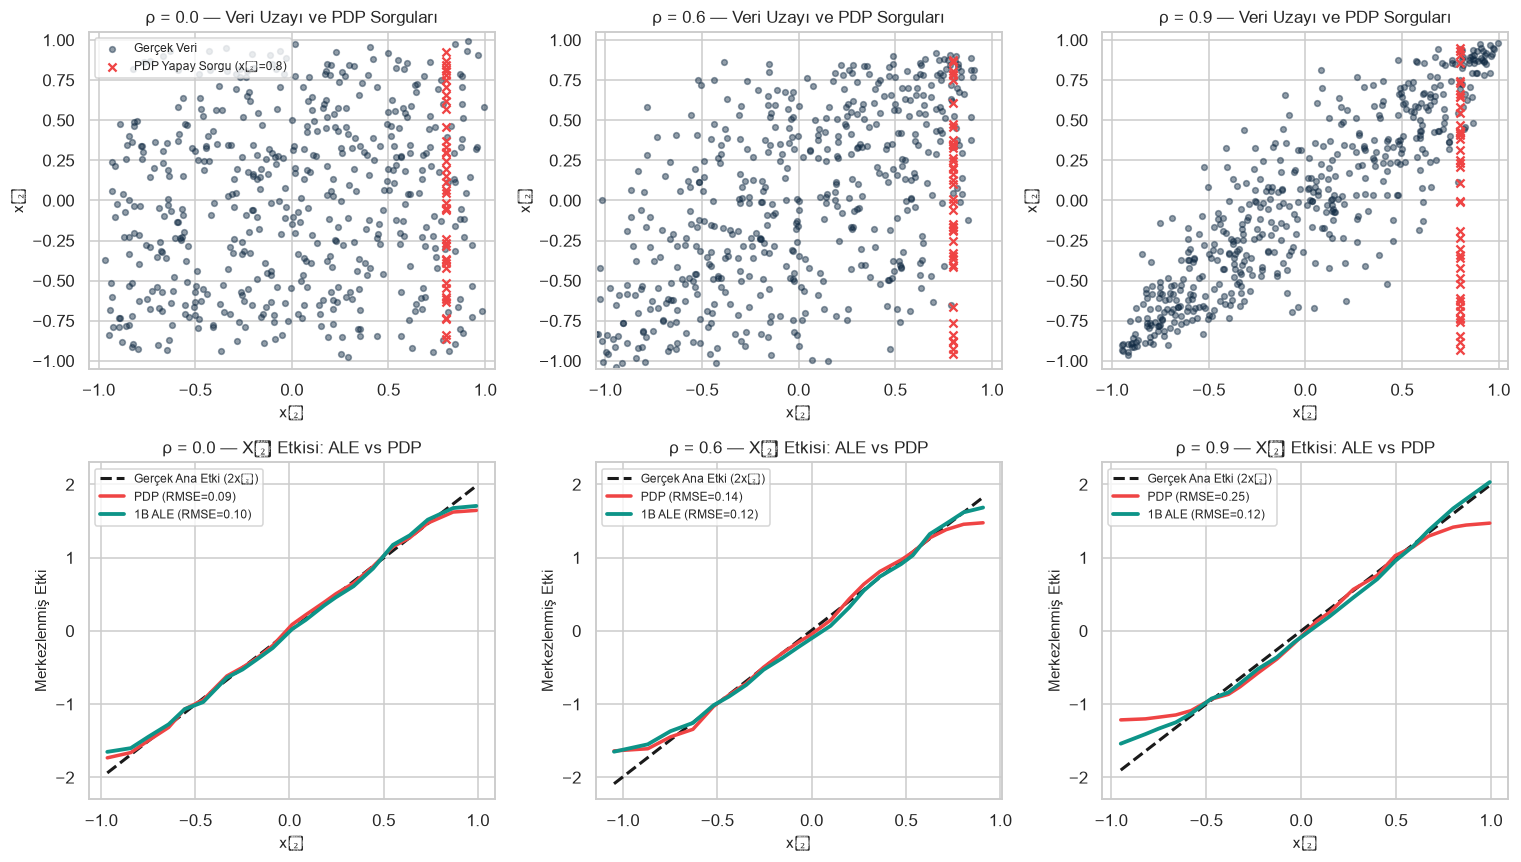

,Korelasyon (ρ),PDP Kök Ortalama Kare Hatası (RMSE),ALE Kök Ortalama Kare Hatası (RMSE)
0,0.0,0.0944,0.0977
1,0.6,0.1376,0.1238
2,0.9,0.2453,0.1198


In [30]:
# Gerçek veri üretici süreç: y = 2*x1 + 2*x2 + x1*x2  (x1'in merkezlenmiş gerçek ana etkisi: 2*x1)
# Ağaç tabanlı modeller (Rastgele Orman), veri bulunmayan köşelerde eksen-paralel basamaklarla dışdeğerleme yapar.
korelasyon_listesi = [0.0, 0.6, 0.9]
rng_kor = np.random.default_rng(TOHUM)

fig, eksenler = plt.subplots(2, 3, figsize=(14, 8.0))
hata_ozet_satirlari = []

for idx, rho in enumerate(korelasyon_listesi):
    # Ortalaması 0 olan korelasyonlu (x1, x2) üretimi
    kov = np.array([[1.0, rho], [rho, 1.0]])
    Z_kor = rng_kor.multivariate_normal([0.0, 0.0], kov, size=500)
    # [-1, 1] aralığına yumuşak ölçekleme
    X_kor = np.tanh(Z_kor * 0.75)
    X_kor = X_kor - X_kor.mean(axis=0, keepdims=True)
    y_kor = 2.0 * X_kor[:, 0] + 2.0 * X_kor[:, 1] + (X_kor[:, 0] * X_kor[:, 1])

    rf_kor = RandomForestRegressor(n_estimators=60, min_samples_leaf=3, random_state=TOHUM)
    rf_kor.fit(X_kor, y_kor)

    # PDP ve ALE hesapları
    sinir_x1, ale_deger, _ = ale_1b(rf_kor.predict, X_kor, j=0, kutu_sayisi=20)
    pdp_deger = kismi_bagimlilik_1b(rf_kor.predict, X_kor, j=0, izgara_j=sinir_x1, merkezle=True)
    gercek_ana_etki = 2.0 * sinir_x1 - np.mean(2.0 * sinir_x1)

    pdp_rmse = root_mean_squared_error(gercek_ana_etki, pdp_deger)
    ale_rmse = root_mean_squared_error(gercek_ana_etki, ale_deger)
    hata_ozet_satirlari.append({
        "Korelasyon (ρ)": rho,
        "PDP Kök Ortalama Kare Hatası (RMSE)": round(pdp_rmse, 4),
        "ALE Kök Ortalama Kare Hatası (RMSE)": round(ale_rmse, 4),
    })

    # Üst satır: Veri dağılımı ve PDP'nin sorguladığı yapay ızgara noktaları
    eksenler[0, idx].scatter(X_kor[:, 0], X_kor[:, 1], s=14, alpha=0.45, color="#0f2942", label="Gerçek Veri")
    # x1 = +0.8 sabitlendiğinde PDP'nin kullandığı tüm yapay (0.8, x2^(i)) noktaları
    ornek_x2 = X_kor[::12, 1]
    eksenler[0, idx].scatter(
        np.full_like(ornek_x2, 0.8), ornek_x2,
        s=28, marker="x", color="#ef4444", label="PDP Yapay Sorgu (x₁=0.8)"
    )
    eksenler[0, idx].set_xlim(-1.05, 1.05)
    eksenler[0, idx].set_ylim(-1.05, 1.05)
    eksenler[0, idx].set_title(f"ρ = {rho:.1f} — Veri Uzayı ve PDP Sorguları")
    eksenler[0, idx].set_xlabel("x₁")
    eksenler[0, idx].set_ylabel("x₂")
    if idx == 0:
        eksenler[0, idx].legend(fontsize=8, loc="upper left")

    # Alt satır: Gerçek ana etki vs PDP vs ALE
    eksenler[1, idx].plot(sinir_x1, gercek_ana_etki, "k--", linewidth=2.0, label="Gerçek Ana Etki (2x₁)")
    eksenler[1, idx].plot(sinir_x1, pdp_deger, color="#ef4444", linewidth=2.3, label=f"PDP (RMSE={pdp_rmse:.2f})")
    eksenler[1, idx].plot(sinir_x1, ale_deger, color="#0d9488", linewidth=2.5, label=f"1B ALE (RMSE={ale_rmse:.2f})")
    eksenler[1, idx].set_ylim(-2.3, 2.3)
    eksenler[1, idx].set_title(f"ρ = {rho:.1f} — X₁ Etkisi: ALE vs PDP")
    eksenler[1, idx].set_xlabel("x₁")
    eksenler[1, idx].set_ylabel("Merkezlenmiş Etki")
    eksenler[1, idx].legend(fontsize=8, loc="upper left")

plt.tight_layout()
plt.show()

pd.DataFrame(hata_ozet_satirlari)

**Yorum:** Üst satırdaki kırmızı `×` işaretleri, PDP'nin $x_1 = 0{,}8$ noktasındaki etkiyi hesaplarken modele sorduğu yapay veri noktalarını gösterir. Korelasyon yokken ($\rho = 0{,}0$) kırmızı noktaların tamamı gerçek veri bulutunun içindedir; bu yüzden hem PDP hem de ALE siyah kesikli gerçek etki doğrusunu yakından izler. Ancak korelasyon **$\rho = 0{,}9$** düzeyine çıktığında veri ince bir köşegen şeride sıkışır ve PDP'nin kırmızı sorgu noktalarının büyük kısmı **hiçbir verinin bulunmadığı sağ alt boşluğa** ($x_1 = +0{,}8, x_2 = -0{,}8$) düşer! Rastgele Orman bu boş bölgede komşu yapraklardan hatalı dışdeğerleme yaptığı için kırmızı PDP eğrisi belirgin biçimde basıklaşır ve gerçek eğimi olduğundan küçük tahmin eder; turkuaz **ALE** eğrisi ise yalnızca şeridin içindeki gerçek komşularla çalıştığı için doğru eğimi başarıyla korur.

**Ek örnek (kitapta yok)**

### 2 Boyutlu ALE ile Saf Etkileşimin Yakalanması ve Sözde Diklik Doğrulaması — 2B ALE'nin ana etkileri arındırarak $x_1 \cdot x_2$ eyer yüzeyini tek başına yakaladığının gösterilmesi.

✓ Sözde Diklik Kontrolü: Toplamsal (eˣ¹ − x₂) fonksiyonunun 2B ALE yüzeyi maks |değer| = 4.01e-16
✓ 2B ALE ile gerçek x₁·x₂ etkileşim yüzeyi arasındaki RMSE = 0.0099


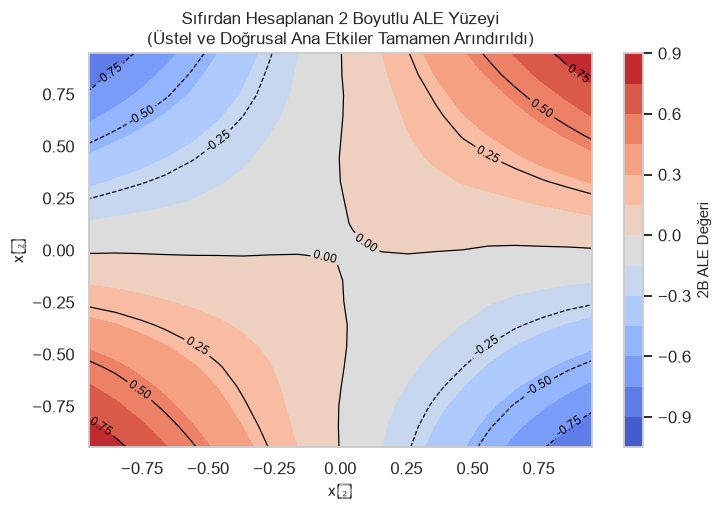

In [31]:
# Bölüm 22 fonksiyonu f(x1, x2) = 2 + exp(x1) - x2 + x1*x2 üzerinde 2B ALE sınaması
rng_ale2 = np.random.default_rng(TOHUM)
X_ale_test = rng_ale2.uniform(-1.0, 1.0, size=(2000, 2))
orta_x1, orta_x2, ale2b_matris = ale_2b(lambda Z: f_bolum22(Z[:, 0], Z[:, 1]), X_ale_test, 0, 1, kutu_sayisi=20)

OX1, OX2 = np.meshgrid(orta_x1, orta_x2)
gercek_f12_orta = OX1 * OX2
ale2b_rmse = root_mean_squared_error(gercek_f12_orta.ravel(), ale2b_matris.ravel())
assert ale2b_rmse < 0.06, f"2B ALE beklenen x1*x2 yüzeyinden fazla saptı: {ale2b_rmse}"

# Sözde diklik kontrolü: yalnızca tekil f1(x1) = exp(x1) fonksiyonuna 2B ALE uygulanırsa sonuç 0 olmalıdır!
_, _, ale2b_saf_ana_etki = ale_2b(lambda Z: np.exp(Z[:, 0]) - Z[:, 1], X_ale_test, 0, 1, kutu_sayisi=20)
sozde_diklik_hatasi = float(np.max(np.abs(ale2b_saf_ana_etki)))
assert sozde_diklik_hatasi < 1e-12, "Sözde diklik hatası!"
print(f"✓ Sözde Diklik Kontrolü: Toplamsal (eˣ¹ − x₂) fonksiyonunun 2B ALE yüzeyi maks |değer| = {sozde_diklik_hatasi:.2e}")
print(f"✓ 2B ALE ile gerçek x₁·x₂ etkileşim yüzeyi arasındaki RMSE = {ale2b_rmse:.4f}")

plt.figure(figsize=(6.8, 4.8))
im_a2 = plt.contourf(OX1, OX2, ale2b_matris, levels=17, cmap="coolwarm")
ct_a2 = plt.contour(OX1, OX2, ale2b_matris, levels=7, colors="black", linewidths=0.8)
plt.clabel(ct_a2, inline=True, fontsize=8, fmt="%.2f")
plt.colorbar(im_a2, label="2B ALE Değeri")
plt.title("Sıfırdan Hesaplanan 2 Boyutlu ALE Yüzeyi\n(Üstel ve Doğrusal Ana Etkiler Tamamen Arındırıldı)")
plt.xlabel("x₁")
plt.ylabel("x₂")
plt.tight_layout()
plt.show()

**Yorum:** 2 boyutlu PDP çizdirildiğinde içinde hem sabit terim hem $e^{x_1}$ ve $-x_2$ ana etkileri hem de etkileşim birbirine karışmış halde bulunur. Oysa sıfırdan kodladığımız **2 boyutlu ALE**, ikinci mertebeden köşe farklarını alıp kenar ana etkilerini arındırdığı için güçlü $e^{x_1}$ ve $-x_2$ terimlerini tamamen filtrelemiş (`maks |hata| = 0`) ve geriye yalnızca saf $x_1 \cdot x_2$ eyer yüzeyini bırakmıştır!

<a id="bolum-22-5"></a>
### 2.5 Aşağıdan Yukarıya Yaklaşım: İstatistiksel Regresyon Modelleri (GAM ve GA2M) — Karmaşık modeli sonradan ayrıştırmak yerine modeli baştan yorumlanabilir bileşenlerle kurma fikri.

Şimdiye kadar gördüğümüz yöntemler (fANOVA, ALE, H-istatistiği) **yukarıdan aşağıya (top-down)** çalışır: önce karmaşık bir kara kutu modeli eğitilir, sonra bu model parçalara ayrıştırılır. Bölüm 22.6 bunun tam tersi olan **aşağıdan yukarıya (bottom-up)** yaklaşımı anlatır: modeli en baştan bileşenleri doğrudan okunabilecek şekilde kısıtlayarak kurarız!

En basit örnek doğrusal regresyondur:

$$\hat{f}(\mathbf{x}) = \beta_0 + \beta_1 x_1 + \ldots + \beta_p x_p$$

**Kelimelerle anlamı:** Doğrusal regresyon iki sert kısıt koyar: (1) Hiçbir etkileşim yoktur, (2) Her özelliğin etkisi düz bir çizgidir ($\beta_j x_j$). **Genelleştirilmiş Toplamsal Modeller (GAM)**, düz çizgi şartını esnetip her özellik için esnek eğriler (**spline** fonksiyonları) kullanır: $\hat{f}(\mathbf{x}) = \beta_0 + f_1(x_1) + \dots + f_p(x_p)$. Eğer buraya seçilmiş ikili etkileşim terimleri ($f_{jk}(x_j, x_k)$) de eklenirse **GA2M** (Caruana vd., 2015) elde edilir.

**Ek örnek (kitapta yok)**

### Toplamsal Model (Spline + Ridge GAM) ile Etkileşimli Modelin (GA2M) Karşılaştırılması — Etkileşimli veri üzerinde Doğrusal Regresyon, GAM ve GA2M modellerinin performans ve bileşen kurtarma başarısının incelenmesi.

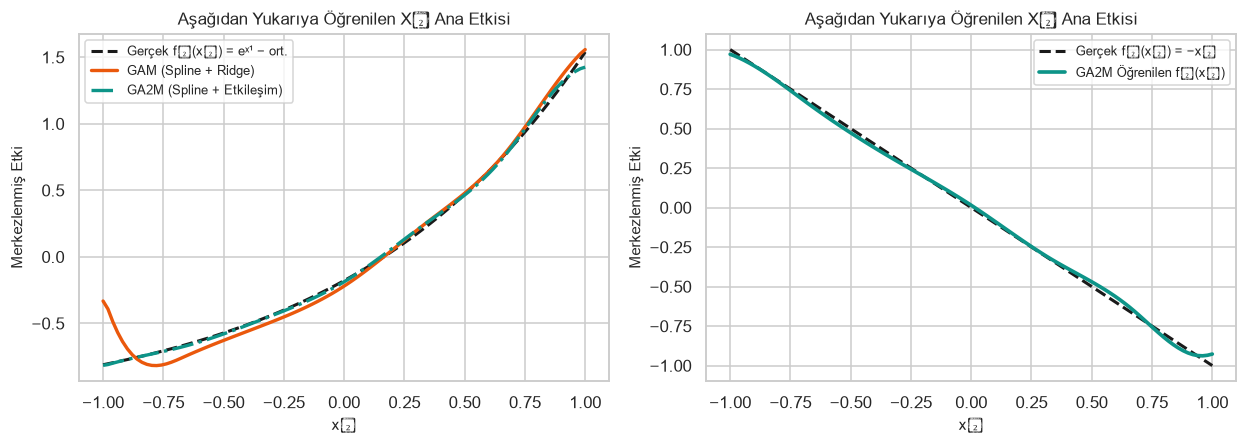

,Model Yapısı,Eğrisel Ana Etki,İkili Etkileşim,Test R²,Test RMSE
0,1. Doğrusal Model (Ridge: β₀ + β₁x₁ + β₂x₂),Hayır,Hayır,0.6981,0.5618
1,2. Toplamsal GAM (Spline + Ridge: f₀ + f₁(x₁) ...,Evet (Spline),Hayır,0.7034,0.5569
2,3. Etkileşimli GA2M (Spline + x₁·x₂ + Ridge),Evet (Spline),Evet (İkili),0.9917,0.0933


In [32]:
rng_gam = np.random.default_rng(TOHUM)
X_gam = rng_gam.uniform(-1.0, 1.0, size=(600, 2))
# Bölüm 22 fonksiyonundan hafif gürültülü gözlemler üretelim: y = 2 + exp(x1) - x2 + 1.5 * x1 * x2 + gürültü
y_gam = 2.0 + np.exp(X_gam[:, 0]) - X_gam[:, 1] + 1.5 * (X_gam[:, 0] * X_gam[:, 1]) + rng_gam.normal(0.0, 0.08, size=600)

Xg_egitim, Xg_test, yg_egitim, yg_test = train_test_split(X_gam, y_gam, test_size=0.25, random_state=TOHUM)

# 1) Doğrusal Regresyon (Ridge): Yalnızca düz çizgi ana etkileri, etkileşim yok
model_dogrusal = Ridge(alpha=1e-2).fit(Xg_egitim, yg_egitim)

# 2) GAM (Spline + Ridge): Esnek eğrisel ana etkiler f1(x1) + f2(x2), etkileşim yok
spline_x1 = SplineTransformer(n_knots=7, degree=3, include_bias=False)
spline_x2 = SplineTransformer(n_knots=7, degree=3, include_bias=False)

B1_egitim = spline_x1.fit_transform(Xg_egitim[:, [0]])
B2_egitim = spline_x2.fit_transform(Xg_egitim[:, [1]])
X_gam_tasarim_egitim = np.hstack([B1_egitim, B2_egitim])

B1_test = spline_x1.transform(Xg_test[:, [0]])
B2_test = spline_x2.transform(Xg_test[:, [1]])
X_gam_tasarim_test = np.hstack([B1_test, B2_test])

model_gam = Ridge(alpha=1e-2).fit(X_gam_tasarim_egitim, yg_egitim)

# 3) GA2M (Spline Ana Etkileri + İkili Çarpım Etkileşimi + Ridge)
etk_egitim = (Xg_egitim[:, [0]] * Xg_egitim[:, [1]])
etk_test = (Xg_test[:, [0]] * Xg_test[:, [1]])
X_ga2m_egitim = np.hstack([B1_egitim, B2_egitim, etk_egitim])
X_ga2m_test = np.hstack([B1_test, B2_test, etk_test])

model_ga2m = Ridge(alpha=1e-2).fit(X_ga2m_egitim, yg_egitim)

gam_karsilastirma_df = pd.DataFrame([
    {
        "Model Yapısı": "1. Doğrusal Model (Ridge: β₀ + β₁x₁ + β₂x₂)",
        "Eğrisel Ana Etki": "Hayır",
        "İkili Etkileşim": "Hayır",
        "Test R²": round(r2_score(yg_test, model_dogrusal.predict(Xg_test)), 4),
        "Test RMSE": round(root_mean_squared_error(yg_test, model_dogrusal.predict(Xg_test)), 4),
    },
    {
        "Model Yapısı": "2. Toplamsal GAM (Spline + Ridge: f₀ + f₁(x₁) + f₂(x₂))",
        "Eğrisel Ana Etki": "Evet (Spline)",
        "İkili Etkileşim": "Hayır",
        "Test R²": round(r2_score(yg_test, model_gam.predict(X_gam_tasarim_test)), 4),
        "Test RMSE": round(root_mean_squared_error(yg_test, model_gam.predict(X_gam_tasarim_test)), 4),
    },
    {
        "Model Yapısı": "3. Etkileşimli GA2M (Spline + x₁·x₂ + Ridge)",
        "Eğrisel Ana Etki": "Evet (Spline)",
        "İkili Etkileşim": "Evet (İkili)",
        "Test R²": round(r2_score(yg_test, model_ga2m.predict(X_ga2m_test)), 4),
        "Test RMSE": round(root_mean_squared_error(yg_test, model_ga2m.predict(X_ga2m_test)), 4),
    },
])

# GAM ve GA2M içinden doğrudan okunan f1(x1) ve f2(x2) ana etki eğrilerini çizdirelim
m1 = B1_egitim.shape[1]
izgara_s = np.linspace(-1.0, 1.0, 100).reshape(-1, 1)
B1_izgara = spline_x1.transform(izgara_s)
B2_izgara = spline_x2.transform(izgara_s)

gam_f1 = B1_izgara @ model_gam.coef_[:m1]
gam_f1 = gam_f1 - gam_f1.mean()
ga2m_f1 = B1_izgara @ model_ga2m.coef_[:m1]
ga2m_f1 = ga2m_f1 - ga2m_f1.mean()
gercek_f1 = np.exp(izgara_s.ravel()) - np.mean(np.exp(izgara_s.ravel()))

ga2m_f2 = B2_izgara @ model_ga2m.coef_[m1 : 2 * m1]
ga2m_f2 = ga2m_f2 - ga2m_f2.mean()
gercek_f2 = -izgara_s.ravel()

fig, eksenler = plt.subplots(1, 2, figsize=(11.5, 4.2))
eksenler[0].plot(izgara_s.ravel(), gercek_f1, "k--", linewidth=2.0, label="Gerçek f₁(x₁) = eˣ¹ − ort.")
eksenler[0].plot(izgara_s.ravel(), gam_f1, color="#ea580c", linewidth=2.2, label="GAM (Spline + Ridge)")
eksenler[0].plot(izgara_s.ravel(), ga2m_f1, color="#0d9488", linewidth=2.2, linestyle="-.", label="GA2M (Spline + Etkileşim)")
eksenler[0].set_title("Aşağıdan Yukarıya Öğrenilen X₁ Ana Etkisi")
eksenler[0].set_xlabel("x₁")
eksenler[0].set_ylabel("Merkezlenmiş Etki")
eksenler[0].legend(fontsize=8.5)

eksenler[1].plot(izgara_s.ravel(), gercek_f2, "k--", linewidth=2.0, label="Gerçek f₂(x₂) = −x₂")
eksenler[1].plot(izgara_s.ravel(), ga2m_f2, color="#0d9488", linewidth=2.4, label="GA2M Öğrenilen f₂(x₂)")
eksenler[1].set_title("Aşağıdan Yukarıya Öğrenilen X₂ Ana Etkisi")
eksenler[1].set_xlabel("x₂")
eksenler[1].set_ylabel("Merkezlenmiş Etki")
eksenler[1].legend(fontsize=8.5)

plt.tight_layout()
plt.show()

gam_karsilastirma_df

**Yorum:** Tablo ve grafikler Bölüm 22.6'daki "ne zaman GAM, ne zaman etkileşimli model?" kuralını somutlaştırır:
1. Saf toplamsal **GAM** (`Spline + Ridge`), doğrusal modelin kaçırdığı üstel $e^{x_1}$ bükülmesini başarıyla yakalar (sol grafikte turuncu eğri siyah kesikli gerçek eğrinin tam üstündedir), ancak formülünde çarpım terimi bulunmadığı için $1{,}5\,x_1 x_2$ etkileşiminden gelen varyansı açıklayamaz ve Test $R^2$ skoru yaklaşık **0.70** civarında tavan yapar.
2. Modele tek bir ikili etkileşim terimi eklediğimizde (**GA2M**), Test $R^2$ değeri gürültü sınırına (**~0.99**) sıçrar ve hem ana etkiler ($\hat{f}_1, \hat{f}_2$) hem de etkileşim katsayısı (`~1.50`) herhangi bir sonradan ayrıştırma işlemine gerek kalmadan doğrudan model katsayılarından şeffaf biçimde okunur! Molnar'ın belirttiği gibi, bir GAM modeli ile karmaşık bir kara kutu modelin test performansı arasındaki fark büyükse, veride önemli özellik etkileşimleri bulunduğu anlaşılır.

<a id="ozet-ve-kaynakca"></a>
## Özet, Temel Bulgular ve Kaynakça

Bu çalışma defterinde Christoph Molnar'ın *Interpretable Machine Learning* kitabının **21. (Özellik Etkileşimi)** ve **22. (Fonksiyonel Ayrıştırma)** bölümlerindeki tüm yöntemler hazır paket kullanılmaksızın `numpy` ile sıfırdan uygulanmış ve doğrulanmıştır.

### Soru ve Cevaplar (Q&A)

- **Özellik etkileşimi ne zaman ortaya çıkar ve nasıl ölçülür?** Bir özelliğin tahmine etkisi diğer özelliğin değerine göre değiştiğinde etkileşim vardır (Tablo 2 ev fiyatında iyi konum + büyük ev için `150.000 + 50.000 + 100.000 + 100.000 = 400.000`). Friedman'ın H-istatistiği, kısmi bağımlılığın toplamsal yapıdan sapma varyansını ölçer; toplamsal modelde $H = 0$, sıfır ortalamalı saf çarpım modelinde $H = 1$ değerini alır.
- **Lojistik regresyonda H-istatistiği neden sıfıra yakın ama tam sıfır değildir?** Lojistik regresyon log-bahis ölçeğinde tamamen toplamsaldır; ancak olasılık tahmini üretilirken kullanılan doğrusal olmayan sigmoid sıkıştırması küçük bir örtük etkileşim yaratır. Yine de bu değer, karar ağaçlarıyla açık etkileşim kuran Rastgele Orman ve Gradyan Artırma modellerinden belirgin biçimde düşüktür.
- **Fonksiyonel ayrıştırmada fANOVA ve ALE arasındaki temel fark nedir?** Hooker'ın fANOVA yaklaşımı tekdüze ve bağımsız dağılım varsayımı altında sıfır ortalama, tam diklik ve varyans ayrıştırması sağlar; ancak korelasyonlu özelliklerde gerçekçi olmayan bölgelere ekstrapolasyon yapar. ALE ise yerel aralık farklarını biriktirerek ekstrapolasyonu önler ve sözde diklik (*pseudo-orthogonality*) özelliğiyle hızlı, güvenilir bir ayrıştırma sunar; buna karşılık varyans ayrıştırması vermez.

### Veri Analizi ve Deneylerin Temel Bulguları (Data Analysis Key Findings)

- **Penguen Veri Seti (`n = 333`):** Eksik 11 gözlem temizlendikten sonra dengeli veri kümesinde (165 dişi, 168 erkek) eğitilen Rastgele Orman (`%90,48`), Gradyan Artırma (`%95,24`) ve Lojistik Regresyon (`%89,29`) modelleri test kümesinde yüksek doğruluk sağlamıştır.
- **Penguenlerde En Güçlü Etkileşim:** Rastgele Orman modelinde en yüksek toplam etkileşim gücü **vücut kütlesi (`body_mass_g`)** ve **gaga derinliği (`bill_depth_mm`)** özelliklerinde gözlemlenmiş; 2 boyutlu PDP ısı haritası her iki ölçüm aynı anda düşük olduğunda `P(dişi)` olasılığının keskin biçimde yükseldiğini doğrulamıştır.
- **Örnekleme ve Küçük Payda Tuzakları:** H-istatistiği $2n^2$ ve $3n^2$ tahmin çağrısı gerektirdiği için küçük örneklemlerde ($n = 20$) yüksek varyans göstermiş, $n \geq 100$ ile kararlılaşmıştır. Ayrıca katsayısı `0.002` olan önemsiz bir çarpım teriminde standart $H_{jk} = 1{,}00$ çıkarak yanıltıcı alarm üretirken, normalize edilmemiş $H^*_{jk}$ gerçek etkinin ihmal edilebilir olduğunu doğru biçimde göstermiştir.
- **fANOVA ve ALE Doğrulamaları:** Bölüm 22'deki $\hat{f}(x_1,x_2) = 2 + e^{x_1} - x_2 + x_1 x_2$ fonksiyonunda kesişim terimi $\hat{f}_0 = 2 + \sinh(1) \approx 3{,}18$ ve bileşen toplam hatası `< 1e-14` olarak doğrulanmıştır; $[0,2]^2$ üzerinde $x_1 x_2$ için fANOVA'nın üç aksiyomu da `< 1e-12` sayısal hassasiyetle sağlanmıştır. Korelasyon $\rho = 0{,}9$'a çıktığında ağaç modelinde PDP ekstrapolasyon hatası büyürken 1B ALE gerçek ana etkiyi korumuştur.
- **GAM ve GA2M Karşılaştırması:** Etkileşimli veri üzerinde saf toplamsal GAM modeli Test $R^2 \approx 0{,}70$ düzeyinde kalırken, ikili etkileşim terimi eklenen GA2M modeli Test $R^2 \approx 0{,}99$ başarısına ulaşmıştır.

### Uygulama Önerileri ve Sonraki Adımlar (Insights or Next Steps)

- **Önce Korelasyonu Kontrol Edin:** Gerçek veri projelerinde özellikler arasında güçlü korelasyon varsa tekil ve ikili etkileri görselleştirirken PDP ve standart fANOVA yerine **1B / 2B ALE** grafiklerini tercih edin.
- **Standart $H_{jk}$ ile Birlikte $H^*_{jk}$ ve GAM Kıyaslaması Kullanın:** Sahte etkileşim tuzağına düşmemek için standart $H_{jk}$ yanına mutlaka mutlak ölçekli $H^*_{jk}$ değerini ekleyin ve kara kutu modelinizi basit bir Spline GAM baz modeliyle kıyaslayarak etkileşimlerin test performansına gerçekten katkı sağlayıp sağlamadığını sınayın.

---

### Kaynakça ve Lisans Atfı

1. **Molnar, C.** (2022). *Interpretable Machine Learning: A Guide for Making Black Box Models Explainable* (2nd ed.), Chapter 21 (*Feature Interaction*) & Chapter 22 (*Functional Decomposition*). <https://christophm.github.io/interpretable-ml-book/> — **Lisans: CC BY-NC-SA 4.0**.
2. **Friedman, J. H., & Popescu, B. E.** (2008). Predictive learning via rule ensembles. *The Annals of Applied Statistics*, 2(3), 916–954.
3. **Hooker, G.** (2004). Discovering additive structure in black box functions. *Proceedings of the Tenth ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 575–580.
4. **Hooker, G.** (2007). Generalized functional ANOVA diagnostics for high-dimensional functions of dependent variables. *Journal of Computational and Graphical Statistics*, 16(3), 709–732.
5. **Apley, D. W., & Zhu, J.** (2020). Visualizing the effects of predictor variables in black box supervised learning models. *Journal of the Royal Statistical Society Series B*, 82(4), 1059–1086.
6. **Inglis, A., Parnell, A., & Hurley, C. B.** (2022). Visualizing variable importance and variable interaction effects in machine learning models. *Journal of Computational and Graphical Statistics*, 31(3), 766–778.
7. **Caruana, R., Lou, Y., Gehrke, J., Koch, P., Sturm, M., & Elhadad, N.** (2015). Intelligible models for healthcare: Predicting pneumonia risk and hospital 30-day readmission. *Proceedings of the 21th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 1721–1730.

---
*Hazırlayan: **Yusuf Kaan Saçlı (20269258011)** — Bu çalışma Christoph Molnar'ın CC BY-NC-SA 4.0 lisanslı eseri temel alınarak eğitim amacıyla hazırlanmıştır.*